This notebook loads the WegenerNet 3D Open-Air Laboratory observations (microwave and infrared radiometer, GNSS, X-band radar, rain gauges), detects and classifies the rain events, extracts the six hours before each rain onset and draws every figure of the paper in figure order.
| Section | Content |
| --- | --- |
| 1 | settings and paths |
| 2 | load the observations |
| 3 | rain events, rain type (warm / cold / mixed) and regime (convective / non-convective) |
| 4 | six-hour pre-onset time series and cloud-only time steps |
| 5 | event categories for the precipitation, cloud-fraction and diurnal figures |
| 6 | figure helpers |
| 7 | figures f01–f13 |
| 8 | appendix figures fA02–fA10 |
| 9 | check of the journal limits (300 dpi, width ≥ 8 cm, < 5 MB per file) |


Run the sections in order. Input data: `data/README.md`.

## 1. Settings

In [1]:
import sys
import shutil
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from matplotlib.colors import BoundaryNorm
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont

warnings.filterwarnings("ignore", message="In a future version of xarray the default value for",
                        category=FutureWarning)

# ----- repository folders (the notebook is run from notebooks/) -----
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
RAW_DIR = ROOT / "data" / "raw"                 # WegenerNet data, not in the repository (see data/README.md)
PROCESSED_DIR = ROOT / "data" / "processed"     # small derived files shipped with the repository
STATIC_DIR = ROOT / "data" / "static"           # photo, topography map and flowcharts
DERIVED_DIR = ROOT / "data" / "derived"         # large derived files (notebook 02)
FIG_DIR = ROOT / "figures"                      # final figures 
PANEL_DIR = FIG_DIR / "panels"                  # single panels of the figures
PANEL_DIR.mkdir(parents=True, exist_ok=True)

TRANSFER_DIR = RAW_DIR / "WegenerNet_Transfer"             # radiometer and GNSS L2a v2.0-rc1, HRR
TSR_DIR = TRANSFER_DIR / "L2a" / "v2.0-rc1" / "TSR"         # radiometer: LWP, IWV, temperature profiles
L1_CARTESIAN_DIR = DERIVED_DIR / "radar_L1_cartesian"       # gridded X-band radar per event (notebook 02)
L2_RADAR_DIR = RAW_DIR / "radar_L2"                         # X-band L2 rain intensity
GAUGE_GRID_DIR = RAW_DIR / "gauge_grid"                     # WegenerNet gauge grid, one file per event day
STATION_DIR = RAW_DIR / "stations"                          # WegenerNet L2 v8 station files

# ----- study period and site -----
PERIOD = slice("2021-04-01", "2025-09-13")
RADIOMETER_XY = (564565.44, 5200868.51)      # microwave radiometer, UTM 33N [m]
DPI = 300

import LWP_IWV_long_analysis
import event_detection
from analysis import (spatial_echo_top_stats, event_echo_top_stats, find_freezing_level,
                      pre_event_segments_with_prior_intensity, extract_pre_events_by_cloud_type,
                      exclude_times_fast)
from notebook_helpers import (resample_to_2p5min, load_station, plot_combined_lwp_iwv_summary,
                              plot_lwp_boxen, plot_iwv_boxen)
from plot_functions import (plot_warm_regime_cloud_grid, plot_warm_regime_cloud_grid_multivar,
                            plot_cold_events_panel)
import event_based_plotting as event_plotting
from event_based_plotting import plot_precip_height_time, plot_radar_var_with_overlay, _get_plot_xlim

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 14})

## 2. Load the observations

* **Microwave radiometer (HATPRO, Raabtal superstation)**: liquid water path LWP (`tclw`, kg m⁻²), integrated water vapour IWV (`tcwv`, kg m⁻²) and temperature profiles, L2a v2.0-rc1 on a 2.5-min grid. `*_dpg_flag` = 0 marks measured (not interpolated) values.
* **Infrared radiometer**: cloud base height (CBH, 1-s HRR data, averaged to 2.5 min here) and zenith cloud masks in two bands (CSX 9.6–11.5 µm, CSR 8–14 µm).
* **GNSS** IWV at station 181.
* **X-band radar** echo-top height (notebook 02), **rain gauges** (WegenerNet L2 v8, stations 43, 44, 151, 156), **ERA5** LWP and IWV at the grid point of the radiometer, and the **convective probability** of each rain event (notebook 02).

In [2]:
# Cloud base height: 1-s HRR data averaged to 2.5-min bins (bins start at the first time stamp)
wegn_cbh_sec = xr.open_mfdataset(
    f"{TRANSFER_DIR}/HRR/SYN/WN3DO_HRR_v2lrc1_SYN_CloudBaseHeightZenith_202*.nc"
).sel(time=slice("2021-04-01", "2025-09-13"))

time_vals = wegn_cbh_sec.time.values
origin = time_vals[0].astype("datetime64[D]")
offset_s = (time_vals - origin).astype("timedelta64[s]").astype(np.int64)
bin_idx = offset_s // 150
bin_idx -= bin_idx[0]
n_bins = bin_idx[-1] + 1
first_bin_offset = (offset_s[0] // 150) * 150
new_time = origin + (np.arange(n_bins) * 150 + first_bin_offset).astype("timedelta64[s]")

resampled_vars = {}
for var_name in ["cbh", "cbh_qcs_flag"]:
    data = wegn_cbh_sec[var_name].values.astype(np.float64)
    valid = ~np.isnan(data)
    sums = np.bincount(bin_idx, weights=np.where(valid, data, 0.0), minlength=n_bins)
    counts = np.bincount(bin_idx, weights=valid.astype(np.float64), minlength=n_bins)
    with np.errstate(invalid="ignore"):
        resampled_vars[var_name] = ("time", np.where(counts > 0, sums / counts, np.nan))
cbh_2p5min_np = xr.Dataset(resampled_vars, coords={"time": new_time})

In [3]:
# Radiometer LWP and IWV, GNSS IWV, infrared cloud masks and temperature profiles (L2a v2.0-rc1)
wegn_lwp_v2 = xr.open_mfdataset(f"{TSR_DIR}/WN3DO_L2a_v2lrc1_TSR_TotalColumnLiquidWater_202*.nc").sel(
    time=slice("2021-04-01", "2025-09-13"))
wegn_iwv_v2 = xr.open_mfdataset(f"{TSR_DIR}/WN3DO_L2a_v2lrc1_TSR_TotalColumnWaterVapor_202*.nc").sel(
    time=slice("2021-04-01", "2025-09-13"))
wegn_iwv_v2_gnss = (
    xr.open_mfdataset(f"{TRANSFER_DIR}/L2a/v2.0-rc1/WSN_GNSS/WN3DO_L2a_v2lrc1_WSN_TotalColumnWaterVapor*.nc")
    .sel(time=slice("2021-04-01", "2025-09-13"))
    .sel(station_number=181)
)
wegn_clmsk_v2x = xr.open_mfdataset(
    f"{TRANSFER_DIR}/L2a/v2.0-rc1/CSX/WN3DO_L2a_v2lrc1_CSX_CloudMaskZenith_202*.nc").sel(time=PERIOD)
wegn_clmsk_v2r = xr.open_mfdataset(
    f"{TRANSFER_DIR}/L2a/v2.0-rc1/CSR/WN3DO_L2a_v2lrc1_CSR_CloudMaskZenith_202*.nc").sel(time=PERIOD)
wegn_tprof = xr.open_mfdataset(f"{TSR_DIR}/WN3DO_L2a_v2lrc1_TSR_TroposphericProfiles_*.nc").sel(
    time=slice("2021-04-01", "2025-09-13"))

# Radar echo-top height (Z_h > 0 dBZ) in a +/- 3 km box around the radiometer (notebook 02)
ds_echo_top = xr.open_dataset(PROCESSED_DIR / "echo_top_height_filtered_202606.nc").sel(
    time=slice("2021-04-01T00:00", "2025-09-13T23:59"))
radar_radiometer_exact = ds_echo_top.where(
    (abs(ds_echo_top.x_utm - RADIOMETER_XY[0]) <= 100) & (abs(ds_echo_top.y_utm - RADIOMETER_XY[1]) <= 100),
    drop=True,
).mean(dim=["x_utm", "y_utm"])

# Rain gauges (5-min precipitation [mm], 2-m temperature)
st = xr.merge([load_station(n, STATION_DIR) for n in (43, 44, 151, 156)]).sel(
    time=slice("2021-04-01T00:00", "2025-09-13T23:59"))

# ERA5 LWP and IWV at the grid point of the radiometer
era5_ts = xr.open_dataset(PROCESSED_DIR / "era5_tclw_tcwv_radiometer.nc").sel(
    time=slice("2021-04-01T00:00", "2025-09-13T23:59"))

# Convective and hail probability of every rain event (notebook 02)
events = xr.open_dataset(PROCESSED_DIR / "summer_events_with_conv_prob_20260630.nc").to_dataframe().reset_index()

In [4]:
# One dataset on the 2.5-min LWP grid: IWV (mean over the radiometer stations), GNSS IWV, CBH, echo top
wegn_iwv_mean = wegn_iwv_v2.mean(dim="station_number")
wegn_lwp_v2 = wegn_lwp_v2.assign(
    tcwv=wegn_iwv_mean.tcwv,
    tcwv_dpg_flag=wegn_iwv_mean.tcwv_dpg_flag,
    tcwv_gnss=wegn_iwv_v2_gnss.tcwv,
    tcwv_gnss_dpg_flag=wegn_iwv_v2_gnss.tcwv_dpg_flag,
    cbh=cbh_2p5min_np.cbh.where(cbh_2p5min_np.cbh > 0),
    cbh_qcs_flag=cbh_2p5min_np.cbh_qcs_flag,
)
wegn_lwp_v2 = wegn_lwp_v2.assign(
    radar_cth=radar_radiometer_exact.echo_top_height.where(radar_radiometer_exact.echo_top_height > 0),
    cloud_depth=radar_radiometer_exact.echo_top_height - wegn_lwp_v2.cbh,
)

# Temperature, relative and absolute humidity at the cloud base (nearest profile level)
wegn_tprof_2p5 = resample_to_2p5min(wegn_tprof)
TIME_TOL = np.timedelta64(5, "m")
tprof_aligned = wegn_tprof_2p5.sel(time=wegn_lwp_v2.time, method="nearest", tolerance=TIME_TOL)

cbh_arr = wegn_lwp_v2["cbh"].values
h_msl_arr = wegn_tprof_2p5["h_msl"].values
cbh_valid = ~np.isnan(cbh_arr)
cbh_safe = np.where(cbh_valid, cbh_arr, h_msl_arr[0])
h_idx = np.abs(h_msl_arr[np.newaxis, :] - cbh_safe[:, np.newaxis]).argmin(axis=1)

profile_to_extract = {"T_profile": "T_cb", "RH_profile": "RH_cb", "AH_profile": "AH_cb"}
for prof_var, cb_name in profile_to_extract.items():
    if prof_var in tprof_aligned:
        vals = tprof_aligned[prof_var].values[np.arange(len(h_idx)), h_idx]
        vals[~cbh_valid] = np.nan
        wegn_lwp_v2[cb_name] = ("time", vals)
if "k_index" in tprof_aligned:
    wegn_lwp_v2["k_index"] = tprof_aligned["k_index"]
for prof_var in profile_to_extract:
    flag_name = prof_var + "_dpg_flag"
    if flag_name in tprof_aligned:
        flag_vals = tprof_aligned[flag_name].values[np.arange(len(h_idx)), h_idx]
        flag_vals[~cbh_valid] = np.nan
        wegn_lwp_v2[flag_name.replace("_profile", "_cb")] = ("time", flag_vals)

## 3. Rain events, rain type and regime

* **−5 °C level** from the radiometer temperature profile (lowest crossing of 268.15 K, linearly interpolated).
* **Rain events** at the superstation (station 156): time steps with > 0.1 mm h⁻¹ that stay above 0.1 mm h⁻¹ in a 15-min window; a dry gap > 120 min separates two events. Events with constant gauge values (standard deviation ≤ 0.0001 mm) are removed.
* **Regime** (April–September): events of the convective-probability file, merged if they are ≤ 2 h apart; **convective** if `prob_q95_q95` ≥ 0.5.
* **Cold season** (October–March): events with a mean 2-m temperature > 2 °C (no snow).
* **Rain type** from the echo top around the onset (Fig. 2): warm rain if median and P90 ≤ H₋₅, cold rain if both > H₋₅, mixed rain if median ≤ H₋₅ < P90.

In [5]:
h_freezing, qc_below, qc_above = find_freezing_level(
    wegn_tprof["T_profile"], wegn_tprof["T_profile_dpg_flag"], threshold=273.15 - 5)
ds_fl = xr.Dataset({"freezing_level": h_freezing, "qc_below": qc_below, "qc_above": qc_above})   # -5 degC level

# measured radiometer time steps (dpg flag 0) and cloudy time steps (LWP > 10 g m-2)
measured_wegnL2_all_lwp = wegn_lwp_v2.where((wegn_lwp_v2.tclw_dpg_flag == 0).compute(), drop=True)
wegnL2_all_iwv_st171 = wegn_iwv_v2.sel(station_number=171)
measured_wegnL2_all_iwv = wegnL2_all_iwv_st171.where((wegnL2_all_iwv_st171.tcwv_dpg_flag == 0).compute(), drop=True)
measured_lwp_above_10g_v2 = measured_wegnL2_all_lwp.where(
    (measured_wegnL2_all_lwp.tclw * 1000 > 10).compute(), drop=True)

# ERA5 at the radiometer grid point
era5_ts_cr = era5_ts.where(
    (abs(era5_ts.longitude - 15.8486) <= 0.1) & (abs(era5_ts.latitude - 46.9582) <= 0.12), drop=True)
era5_radiometer_location_lwp_min = era5_ts_cr.where(era5_ts_cr.tclw * 1000 > 10, drop=True)

In [6]:
# rain events at the superstation
precip_times = LWP_IWV_long_analysis.select_precip_timesteps(st.sel(station=156), roll_time=3)
all_events = LWP_IWV_long_analysis.detect_events_vectorized(precip_times, gap_threshold_minutes=120)
all_event_warm = LWP_IWV_long_analysis.merge_close_events_vectorized(
    events.loc[(events["start"].dt.month > 3) & (events["start"].dt.month < 10)], merge_threshold_hours=2)

char_all_events = event_detection.calculate_event_statistics(
    all_events, precip_times.set_index("time").to_xarray(), "precip_val_g")
all_cold_events = char_all_events.loc[(char_all_events["start"].dt.month <= 3) | (char_all_events["start"].dt.month >= 10)]
filtered_all_events = char_all_events[char_all_events.std_value > 0.0001]
filtered_cold_events = all_cold_events[all_cold_events.std_value > 0.0001]
filtered_cold_events_no_snow = filtered_cold_events[filtered_cold_events.mean_temp > 2]

warm_events_with_conv_index = event_detection.calculate_event_statistics(
    all_event_warm[all_event_warm.prob_q95_q95.notnull()], precip_times.set_index("time").to_xarray(), "precip_val_g")
filtered_events_with_conv_index = warm_events_with_conv_index[warm_events_with_conv_index.std_value > 0.0001]
filtered_conv_events = filtered_events_with_conv_index.loc[filtered_events_with_conv_index["prob_q95_q95"] >= 0.5]
filtered_non_conv_events = filtered_events_with_conv_index.loc[filtered_events_with_conv_index["prob_q95_q95"] < 0.5]
filtered_events_with_conv_index.to_csv(PROCESSED_DIR / "filtered_events_with_conv_index.csv")   # input of notebook 02, Fig. A1
print("cold-season events (no snow):", len(filtered_cold_events_no_snow))
print("warm-season events with convective index:", len(filtered_events_with_conv_index),
      f"(convective {len(filtered_conv_events)}, non-convective {len(filtered_non_conv_events)})")

cold-season events (no snow): 147
warm-season events with convective index: 390 (convective 215, non-convective 175)


In [7]:
# echo-top statistics around each onset and rain type
char_echo_top = spatial_echo_top_stats(ds_echo_top, filtered_all_events, x_dim="x_utm", y_dim="y_utm").sel(
    time=slice("2021-04-01", "2025-09-13"))
event_stats_clouds = event_echo_top_stats(char_echo_top, filtered_all_events, ds_fl,
                                          fl_var="freezing_level", fl_qc_var="qc_below")

ds = event_stats_clouds
med_use = ds.check_dur_ev_med.fillna(ds.ev_median_m)          # echo top around the onset, else the hour before
p90_use = ds.check_dur_ev_med_p90.fillna(ds.ev_median_s_p90)
fl = ds.freezing_level_m                                      # -5 degC level, 60 to 30 min before onset
valid = med_use.notnull() & p90_use.notnull() & fl.notnull()

liquid_mask = valid & (med_use <= fl) & (p90_use <= fl)       # warm rain
ice_mask = valid & (med_use > fl) & (p90_use > fl)            # cold rain
mixed_mask = valid & (med_use <= fl) & (p90_use > fl)         # mixed rain

liquid_clouds = ds.where(liquid_mask, drop=True).compute()
ice_clouds = ds.where(ice_mask, drop=True).compute()
mixed = ds.where(mixed_mask, drop=True).compute()
cloud_type_datasets = {"liquid": liquid_clouds, "ice": ice_clouds, "mixed": mixed}
phase_starts = {name: set(pd.to_datetime(ds["start"].where(mask, drop=True).values))
                for name, mask in [("liquid", liquid_mask), ("ice", ice_mask), ("mixed", mixed_mask)]}
print(f"warm rain {int(liquid_mask.sum())}, cold rain {int(ice_mask.sum())}, mixed rain {int(mixed_mask.sum())}")

warm rain 57, cold rain 244, mixed rain 61


## 4. Six-hour pre-onset time series and cloud-only time steps

Cloudy measured radiometer time steps (LWP > 10 g m⁻²) in the six hours before each rain onset. *Cloud-only* time steps are cloudy time steps that are neither within six hours before an event nor during an event.

In [8]:
pre_all_events = pre_event_segments_with_prior_intensity(
    filtered_all_events, measured_lwp_above_10g_v2, flag_var="tclw_dpg_flag", lookback_hours=6, buffer_minutes=0)
pre_all = xr.concat(pre_all_events[0], dim="time")

pre_warm_events_lwp = pre_event_segments_with_prior_intensity(
    filtered_events_with_conv_index, measured_lwp_above_10g_v2, flag_var="tclw_dpg_flag",
    lookback_hours=6, buffer_minutes=0)
pre_warm_lwp = xr.concat(pre_warm_events_lwp[0], dim="time")
pre_warm_by_cloud = extract_pre_events_by_cloud_type(
    filtered_events_with_conv_index, cloud_type_datasets, measured_lwp_above_10g_v2, flag_var="tclw_dpg_flag")

pre_cold_events = pre_event_segments_with_prior_intensity(
    filtered_cold_events_no_snow, measured_lwp_above_10g_v2, flag_var="tclw_dpg_flag",
    lookback_hours=6, buffer_minutes=0)
pre_cold = xr.concat(pre_cold_events[0], dim="time")

measured_cloudy_times_all = wegn_lwp_v2.where((wegn_lwp_v2.tclw * 1000 > 10).compute(), drop=True)
X_filtered = exclude_times_fast(measured_lwp_above_10g_v2.time, pre_all.time, all_events)
only_cloud_times = measured_cloudy_times_all.sel(time=X_filtered[0])

## 5. Event categories for the precipitation, cloud-fraction and diurnal figures

Warm-season events split into convective / non-convective and warm / cold / mixed rain; hail events (`prob_hail` ≥ 0.5) are removed, and an event is kept only if it has at least one measured radiometer time step with LWP > 10 g m⁻² in [onset − 6 h, onset]. The cold-season no-snow events form a seventh group.

The radiometer variables are put in one table on the 2.5-min grid (`l2a`): LWP (g m⁻²), IWV of the radiometer (station 171) and GNSS, and the infrared cloud masks (0 = clear, 1 = cloud) with their flags. `l2a_measured`: measured LWP (clear and cloudy); `l2a_cloudy`: measured LWP > 10 g m⁻².

In [9]:
grid = wegn_lwp_v2.time


def on_grid(data_array):
    """Variable on the L2a LWP time steps, without the station coordinate (NaN where it has no data)."""
    return data_array.reset_coords(drop=True).reindex(time=grid)


l2a = xr.Dataset({
    "lwp": wegn_lwp_v2.tclw.astype("float64") * 1000.0,                     # g m-2
    "lwp_flag": wegn_lwp_v2.tclw_dpg_flag,
    "iwv": on_grid(wegnL2_all_iwv_st171.tcwv),
    "iwv_flag": on_grid(wegnL2_all_iwv_st171.tcwv_dpg_flag),
    "iwv_gnss": on_grid(wegn_iwv_v2_gnss.tcwv),
    "iwv_gnss_flag": on_grid(wegn_iwv_v2_gnss.tcwv_dpg_flag),
    "csx": on_grid(wegn_clmsk_v2x.cloud_binary_mask_zenith),
    "csx_flag": on_grid(wegn_clmsk_v2x.cloud_binary_mask_zenith_dpg_flag),
    "csr": on_grid(wegn_clmsk_v2r.cloud_binary_mask_zenith),
    "csr_flag": on_grid(wegn_clmsk_v2r.cloud_binary_mask_zenith_dpg_flag),
}).to_dataframe().astype("float64")

l2a_measured = l2a[(l2a["lwp_flag"] == 0) & l2a["lwp"].notna()]
l2a_cloudy = l2a_measured[l2a_measured["lwp"] > 10]
print(f"measured time steps: {len(l2a_measured)}; with LWP > 10 g m-2: {len(l2a_cloudy)}")

measured time steps: 774537; with LWP > 10 g m-2: 258420


In [10]:
# ----- pre-onset window and time bins -----
LOOKBACK_MINUTES = 360
BIN_MINUTES = 10
INCLUDE_ONSET_SAMPLE = True        # the time step exactly at the onset goes into the last bin
N_BINS = LOOKBACK_MINUTES // BIN_MINUTES
BIN_CENTERS_MIN = -LOOKBACK_MINUTES + (np.arange(N_BINS) + 0.5) * BIN_MINUTES

RAIN_TYPE_ROWS = [("liquid", "Warm rain"), ("ice", "Cold rain"), ("mixed", "Mixed rain")]
RAIN_TYPES = [phase for phase, _ in RAIN_TYPE_ROWS]
REGIME_COLUMNS = ["Convective", "Non-convective"]
PANELS = [(row, col, phase, rain_name, regime)
          for row, (phase, rain_name) in enumerate(RAIN_TYPE_ROWS)
          for col, regime in enumerate(REGIME_COLUMNS)]


def time_bin(times, onset, bin_minutes, n_bins):
    """Bin number of every sample: 0 = oldest bin, n_bins - 1 = bin just before the onset."""
    return np.asarray((times - onset) // pd.Timedelta(minutes=bin_minutes), dtype=int) + n_bins


def pre_onset_window(table, onset, include_onset=True):
    """Rows of a time-indexed table in the LOOKBACK_MINUTES before an onset, and their bin numbers."""
    end = onset if include_onset else onset - pd.Timedelta(nanoseconds=1)
    window = table.loc[onset - pd.Timedelta(minutes=LOOKBACK_MINUTES):end]
    bins = np.minimum(time_bin(window.index, onset, BIN_MINUTES, N_BINS), N_BINS - 1)
    return window, bins


def bin_statistic(bins, values, n_bins, how="mean"):
    """Mean (or median) of the values in each bin; empty bins are NaN."""
    result = np.full(n_bins, np.nan)
    for b in np.unique(bins):
        in_bin = values[bins == b]
        result[b] = np.mean(in_bin) if how == "mean" else np.median(in_bin)
    return result


def nan_average(array, how="mean"):
    """Mean (or median) over the first axis, ignoring NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        return np.nanmean(array, axis=0) if how == "mean" else np.nanmedian(array, axis=0)


def composite(curves, n_bins, how="mean"):
    """Composite of several events (equal weight) and the number of events with a value per bin."""
    if len(curves) == 0:
        return np.full(n_bins, np.nan), np.zeros(n_bins, dtype=int)
    array = np.array(curves)
    return nan_average(array, how), np.isfinite(array).sum(axis=0)


def n_events_with_data(curves):
    """Number of events whose curve has at least one valid bin."""
    return int(sum(np.isfinite(curve).any() for curve in curves))


# ----- event categories -----
conv_no_hail = filtered_conv_events[filtered_conv_events["prob_hail"] < 0.5]
rows = []
for regime, regime_events in [("Convective", conv_no_hail), ("Non-convective", filtered_non_conv_events)]:
    for _, event in regime_events.iterrows():
        start, end = pd.Timestamp(event["start"]), pd.Timestamp(event["end"])
        for rain_type in RAIN_TYPES:
            if start in phase_starts[rain_type]:
                rows.append({"start": start, "end": end, "phase": rain_type, "regime": regime,
                             "duration_minutes": (end - start).total_seconds() / 60})
precip_events = (pd.DataFrame(rows, columns=["start", "end", "duration_minutes", "phase", "regime"])
                 .drop_duplicates(["start", "phase", "regime"]).sort_values("start").reset_index(drop=True))

cloudy_lwp_times = l2a_cloudy.index


def has_cloudy_lwp(onset):
    """True if a measured L2a time step with LWP > 10 g m-2 exists in [onset - 6 h, onset]."""
    return bool(((cloudy_lwp_times >= onset - pd.Timedelta(minutes=LOOKBACK_MINUTES))
                 & (cloudy_lwp_times <= onset)).any())


precip_events = precip_events[precip_events["start"].map(has_cloudy_lwp)].reset_index(drop=True)
regime_starts = {}
for phase, _ in RAIN_TYPE_ROWS:
    for regime in REGIME_COLUMNS:
        selected = precip_events[(precip_events["phase"] == phase) & (precip_events["regime"] == regime)]
        regime_starts[f"{regime} · {phase}"] = sorted(selected["start"])
cold_starts = set(pd.to_datetime(filtered_cold_events_no_snow["start"]).dropna())
regime_starts["Cold season · no snow"] = sorted(o for o in cold_starts if has_cloudy_lwp(o))
print("Rain onsets by category:", {name: len(s) for name, s in regime_starts.items()})

Rain onsets by category: {'Convective · liquid': 15, 'Non-convective · liquid': 40, 'Convective · ice': 151, 'Non-convective · ice': 89, 'Convective · mixed': 34, 'Non-convective · mixed': 27, 'Cold season · no snow': 116}


In [11]:
# ----- precipitation over the storm duration (stations) and time-averaged maps (gauge grid) -----
PRECIP_STATISTIC = "mean"          # within a bin, within an event map and across events
STORM_PHASE_BINS = 20              # 5 % of the event duration per bin
STORM_PERCENT = (np.arange(STORM_PHASE_BINS) + 0.5) * (100 / STORM_PHASE_BINS)
STATION_LABELS = {156: "Superstation", 43: "Station 43"}
STATION_VISIBLE = {156: True, 43: False}

precip_event_catalog = precip_events.rename_axis("event").to_xarray().set_coords(["phase", "regime"])


def select_precip_events(phase, regime):
    """Event characteristics of one rain type and regime as an xarray Dataset."""
    selected = (precip_event_catalog.phase.values == phase) & (precip_event_catalog.regime.values == regime)
    return precip_event_catalog.isel(event=np.flatnonzero(selected))


def event_days(start, end):
    return pd.date_range(start.normalize(), end.normalize(), freq="D")


def to_storm_phase_bins(times, rates, start, end):
    """Mean rain rate of one event in STORM_PHASE_BINS equal fractions of its duration."""
    duration_seconds = (end - start).total_seconds()
    if duration_seconds <= 0:
        return np.full(STORM_PHASE_BINS, np.nan)
    fraction = np.asarray((pd.DatetimeIndex(times) - start).total_seconds() / duration_seconds)
    rates = np.asarray(rates, dtype=float)
    keep = (fraction >= 0) & (fraction <= 1) & np.isfinite(rates)
    bins = np.minimum((fraction[keep] * STORM_PHASE_BINS).astype(int), STORM_PHASE_BINS - 1)
    return bin_statistic(bins, rates[keep], STORM_PHASE_BINS, PRECIP_STATISTIC)


def build_station_series(events):
    """{station: {event start: 0-100 % curve}} of stations 156 and 43 (mm per 5 min -> mm h-1)."""
    series = {}
    for station_id in (156, 43):
        amount = st.sel(station=station_id)["precip"].to_series()
        rate = amount.where(amount >= 0) * 12.0
        series[station_id] = {}
        for event in events.itertuples(index=False):
            samples = rate.loc[event.start:event.end]
            series[station_id][event.start] = to_storm_phase_bins(samples.index, samples.to_numpy(),
                                                                  event.start, event.end)
    return series


def read_gauge_grid_event(event):
    """Gauge-grid rain rate (mm h-1) of one complete event, or (None, None) if a 5-min step is missing."""
    parts = []
    for day in event_days(event.start, event.end):
        file = GAUGE_GRID_DIR / f"WN_L2_BD_v8_UTM_TF1_UTC_{day:%Y-%m-%d}.nc"
        if not file.exists():
            return None, None
        with xr.open_dataset(file) as day_ds:
            part = day_ds["Precip"].sel(time=slice(event.start, event.end))
            if part.sizes["time"] > 0:
                parts.append(part.where(part >= 0).load() * 12.0)
    if not parts:
        return None, None
    cube = xr.concat(parts, dim="time").sortby("time")
    cube = cube.isel(time=~cube.get_index("time").duplicated())
    times = cube.get_index("time")
    expected = pd.date_range(event.start, event.end, freq="5min")
    if len(expected) == 0 or not expected.isin(times).all():
        return None, None
    return times, cube


def build_event_maps(events):
    """Time-averaged gauge-grid map of every complete event."""
    fields = {}
    for event in events.itertuples(index=False):
        _, cube = read_gauge_grid_event(event)
        if cube is None:
            continue
        field = nan_average(cube.values, PRECIP_STATISTIC)
        if np.isfinite(field).any():
            fields[event.start] = cube.isel(time=0, drop=True).copy(data=field)
    return fields


unique_events = precip_events.drop_duplicates("start")
station_series = build_station_series(unique_events)
gauge_grid_fields = build_event_maps(unique_events)

cold_events = (filtered_cold_events_no_snow[pd.to_datetime(filtered_cold_events_no_snow["start"])
                                            .isin(regime_starts["Cold season · no snow"])][["start", "end"]]
               .drop_duplicates("start").sort_values("start").copy())
cold_events["start"] = pd.to_datetime(cold_events["start"])
cold_events["end"] = pd.to_datetime(cold_events["end"])
overall_grid_maps = {**gauge_grid_fields, **build_event_maps(cold_events)}
print(f"gauge-grid maps: {len(gauge_grid_fields)} warm-season and {len(overall_grid_maps)} warm + cold-season events")

gauge-grid maps: 355 warm-season and 468 warm + cold-season events


In [12]:
# ----- cloud fraction before the onset (all measured time steps) -----
unique_onsets = sorted(set().union(*regime_starts.values()))
CF_METRICS = ["cf_lwp", "cf_csx", "cf_csr"]


def l2a_cloud_fraction_curves(onset):
    """Cloud fraction from LWP > 10 g m-2 and from the CSX and CSR masks in each time bin."""
    window, bins = pre_onset_window(l2a_measured, onset, INCLUDE_ONSET_SAMPLE)
    cloudy = window["lwp"].to_numpy() > 10
    result = {"cf_lwp": bin_statistic(bins, cloudy.astype(float), N_BINS)}
    for name in ["csx", "csr"]:
        valid = ((window[f"{name}_flag"] == 0) & window[name].isin([0, 1])).to_numpy()
        result[f"cf_{name}"] = bin_statistic(bins[valid], window[name].to_numpy()[valid], N_BINS)
    return result


def summarize_categories(event_curves, metrics, n_bins, how="mean"):
    """Composite curves, events per bin and events with data for every category."""
    composites, counts, table_rows = {}, {}, []
    for category, starts in regime_starts.items():
        composites[category], counts[category] = {}, {}
        row = {"classified_onsets": len(starts)}
        for metric in metrics:
            curves = [event_curves[start][metric] for start in starts]
            composites[category][metric], counts[category][metric] = composite(curves, n_bins, how)
            row[f"{metric}_events"] = n_events_with_data(curves)
        table_rows.append(pd.Series(row, name=category))
    return composites, counts, pd.DataFrame(table_rows)


cf_curves = {onset: l2a_cloud_fraction_curves(onset) for onset in unique_onsets}
cf_composites, cf_counts, cf_coverage = summarize_categories(cf_curves, CF_METRICS, N_BINS)

# ----- hour of day of the cloudy pre-onset time steps -----
DIURNAL_HOURS = np.arange(24)
diurnal_lwp_counts = pd.DataFrame(index=DIURNAL_HOURS)
for _, _, phase, _, regime in PANELS:
    key = f"{regime} · {phase}"
    counts = np.zeros(24, dtype=int)
    for onset in regime_starts[key]:
        window, _ = pre_onset_window(l2a_cloudy, onset, INCLUDE_ONSET_SAMPLE)
        counts += np.bincount(window.index.hour, minlength=24)
    diurnal_lwp_counts[key] = counts
cf_coverage

,classified_onsets,cf_lwp_events,cf_csx_events,cf_csr_events
Convective · liquid,15,15,13,7
Non-convective · liquid,40,40,31,18
Convective · ice,151,151,120,67
Non-convective · ice,89,89,60,45
Convective · mixed,34,34,32,8
Non-convective · mixed,27,27,18,12
Cold season · no snow,116,116,62,67


## 6. Figure helpers

* `save_single` / `save_composite`: final files in `figures/`. A composite is a list of rows; each row is a list of panel images placed side by side (top-aligned), and rows are centred below each other. Panels keep their pixel size (300 dpi, same font sizes); rows with `fit_width` are scaled to the width of another row. Labels (a), (b), (c) are written above the panels.
* `utm33n_to_lonlat`, `set_lonlat_ticks`, ...: map axes in longitude / latitude.
* `plot_event`: the three height–time figures of one rain event.

In [13]:
LABEL_HEIGHT, GAP = 80, 40    # px: band for the panel label, space between panels and rows
LABEL_FONT = ImageFont.truetype(
    font_manager.findfont(font_manager.FontProperties(family="DejaVu Sans", weight="bold")), 60)


def open_rgb(path):
    """Open an image as RGB on a white background."""
    image = Image.open(path)
    if image.mode in ("RGBA", "LA", "P"):
        image = image.convert("RGBA")
        background = Image.new("RGB", image.size, "white")
        background.paste(image, mask=image.split()[-1])
        return background
    return image.convert("RGB")


def save_single(name, source):
    """Final single-panel figure: PNG (PDFs are rendered at 300 dpi with pdftoppm)."""
    out = FIG_DIR / f"{name}.png"
    if Path(source).suffix == ".pdf":
        subprocess.run(["pdftoppm", "-r", str(DPI), "-png", "-singlefile", str(source), str(FIG_DIR / name)],
                       check=True)
        source = out
    open_rgb(source).save(out, dpi=(DPI, DPI), optimize=True)
    return out


def save_composite(name, rows):
    """Final multi-panel figure; rows = [{"panels": [path, ...], "fit_width": row index (optional)}, ...]."""
    built, row_widths = [], []
    for row in rows:
        images = [open_rgb(p) for p in row["panels"]]
        if "fit_width" in row:
            target = row_widths[row["fit_width"]]
            height = round((target - GAP * (len(images) - 1)) / sum(im.width / im.height for im in images))
            images = [im.resize((round(im.width * height / im.height), height), Image.LANCZOS) for im in images]
        built.append(images)
        row_widths.append(sum(im.width for im in images) + GAP * (len(images) - 1))
    row_heights = [LABEL_HEIGHT + max(im.height for im in images) for images in built]
    canvas = Image.new("RGB", (max(row_widths), sum(row_heights) + GAP * (len(built) - 1)), "white")
    draw = ImageDraw.Draw(canvas)
    n_panel, y = 0, 0
    for images, row_width, row_height in zip(built, row_widths, row_heights):
        x = (canvas.width - row_width) // 2
        for im in images:
            canvas.paste(im, (x, y + LABEL_HEIGHT))
            draw.text((x + 10, y + 5), f"({chr(ord('a') + n_panel)})", fill="black", font=LABEL_FONT)
            n_panel += 1
            x += im.width + GAP
        y += row_height + GAP
    out = FIG_DIR / f"{name}.png"
    canvas.save(out, dpi=(DPI, DPI), optimize=True)
    return out


def utm33n_to_lonlat(x, y):
    """WGS84 UTM zone 33N (m) to longitude and latitude (deg), NumPy only."""
    x, y = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    a, f = 6378137.0, 1 / 298.257223563
    e2 = f * (2 - f)
    ep2 = e2 / (1 - e2)
    k0 = 0.9996
    e1 = (1 - np.sqrt(1 - e2)) / (1 + np.sqrt(1 - e2))
    mu = (y / k0) / (a * (1 - e2 / 4 - 3 * e2**2 / 64 - 5 * e2**3 / 256))
    phi1 = (mu + (3 * e1 / 2 - 27 * e1**3 / 32) * np.sin(2 * mu)
            + (21 * e1**2 / 16 - 55 * e1**4 / 32) * np.sin(4 * mu)
            + 151 * e1**3 / 96 * np.sin(6 * mu) + 1097 * e1**4 / 512 * np.sin(8 * mu))
    sin_phi, cos_phi = np.sin(phi1), np.cos(phi1)
    c1, t1 = ep2 * cos_phi**2, np.tan(phi1)**2
    n1 = a / np.sqrt(1 - e2 * sin_phi**2)
    r1 = a * (1 - e2) / (1 - e2 * sin_phi**2)**1.5
    d = (x - 500000) / (n1 * k0)
    lat = (phi1 - (n1 * np.tan(phi1) / r1) *
           (d**2 / 2 - (5 + 3*t1 + 10*c1 - 4*c1**2 - 9*ep2) * d**4 / 24
            + (61 + 90*t1 + 298*c1 + 45*t1**2 - 252*ep2 - 3*c1**2) * d**6 / 720))
    lon = (np.deg2rad(15) + (d - (1 + 2*t1 + c1) * d**3 / 6
                             + (5 - 2*c1 + 28*t1 - 3*c1**2 + 8*ep2 + 24*t1**2) * d**5 / 120) / cos_phi)
    return np.rad2deg(lon), np.rad2deg(lat)


def set_lonlat_ticks(ax, extent, n_ticks=3):
    """Label UTM axes with longitude / latitude along the centre lines of the map."""
    x_ticks = np.linspace(extent[0], extent[1], n_ticks)
    y_ticks = np.linspace(extent[2], extent[3], n_ticks)
    lon, _ = utm33n_to_lonlat(x_ticks, (extent[2] + extent[3]) / 2)
    _, lat = utm33n_to_lonlat((extent[0] + extent[1]) / 2, y_ticks)
    ax.set_xticks(x_ticks, labels=[f"{value:.2f}°" for value in lon])
    ax.set_yticks(y_ticks, labels=[f"{value:.2f}°" for value in lat])


def map_extent(field):
    """Outer pixel edges (UTM m) of a map with X and Y at the pixel centres."""
    x, y = field.X.values, field.Y.values
    dx, dy = np.median(np.diff(x)), np.median(np.diff(y))
    return (x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2)


def map_color_scale(maps, vmin=0, vmax=None, n_levels=11, cmap="Blues", gamma=1):
    """Discrete colour scale: colour map, normalisation and level boundaries."""
    if vmax is None:
        positive = [m[m > vmin] for m in maps]
        vmax = max((np.nanpercentile(p, 99) for p in positive if p.size), default=vmin + 1)
    levels = vmin + (vmax - vmin) * np.linspace(0, 1, n_levels) ** (1 / gamma)
    color_map = plt.get_cmap(cmap)
    return color_map, BoundaryNorm(levels, color_map.N, clip=True), levels


def format_pre_onset_panel(ax, row, col, rain_name, regime, ylabel):
    """Titles, labels, limits and the hatched last 15 min of a pre-onset panel."""
    if row == 0:
        ax.set_title(regime, fontsize=13, fontweight="bold")
    if col == 0:
        ax.set_ylabel(f"{rain_name}\n{ylabel}")
    if row == len(RAIN_TYPE_ROWS) - 1:
        ax.set_xlabel("Minutes before rain onset")
    ax.set_xlim(-LOOKBACK_MINUTES, 0)
    ax.set_xticks(np.arange(-LOOKBACK_MINUTES, 1, 60))
    ax.grid(alpha=0.25)
    ax.axvspan(-15, 0, facecolor="none", edgecolor="0.55", hatch="xx", linewidth=0.6, zorder=5)


def add_event_count_axis(ax, x, counts_and_colors, n_events):
    """Faint dotted curves on a second y axis: number of events with a value in each bin."""
    ax_count = ax.twinx()
    for counts, color in counts_and_colors:
        ax_count.plot(x, counts, color=color, linestyle=":", linewidth=1.0, alpha=0.35)
    ax_count.set_ylim(0, max(1, n_events) * 1.1)
    ax_count.set_ylabel("Valid events / bin", color="0.45", fontsize=9)
    ax_count.tick_params(axis="y", colors="0.45", labelsize=8)
    ax_count.spines["right"].set_color("0.7")
    ax_count.patch.set_visible(False)

In [14]:
# ----- single rain events (f10-f13, fA05-fA10) -----
# The colour ranges and time axes were set for each event to show its structure.
EVENT_SETTINGS = {
    "2023-06-08": {"l1_file": "processedL1_2023-06-08_13-40.nc", "xlim": ("10:00", "17:30"),
                   "zh": (0, 45, 7), "zdr": (0.1, 3.3, 9), "precip": (0.1, 21.1, 8)},
    "2024-06-12": {"l1_file": "processedL1_2024-06-12_07-25.nc", "xlim": ("03:30", "08:30"),
                   "zh": (0, 35, 8), "zdr": (0.1, 2.1, 6), "precip": (0.1, 5.1, 6)},
    "2024-08-19": {"l1_file": "processedL1_2024-08-19_19-15.nc", "xlim": ("16:00", "19:30"),
                   "zh": (0, 35, 8), "zdr": (0.1, 2.6, 6), "precip": (0.1, 5.0, 8)},
    "2024-05-16": {"l1_file": "processedL1_2024-05-16_18-50.nc", "xlim": ("14:00", "19:30"),
                   "zh": (0, 35, 8), "zdr": (0.1, 2.1, 6), "precip": (0.1, 3.1, 6)},
    "2025-03-16": {"l1_file": "processedL1_2025-03-16_12-20.nc", "xlim": ("07:00", "16:30"),
                   "zh": (0, 30, 7), "zdr": (0.1, 2.1, 6), "precip": (0.1, 2.6, 6)},
}
EVENT_PLOT_DEFAULTS = {
    "figsize": (8, 5), "height_ylim": (0, 6000), "event_span_color": "skyblue", "event_span_alpha": 0.5,
    "t0_color": "black", "t0_lw": 1.3, "t0_alpha": 1.0, "t0_smoothing_window": 5, "t0_band_color": "gray",
    "t0_band_alpha": 0.5, "grid_alpha": 0.5, "savefig_dpi": 300,
}
st156_csv = (
    pd.read_csv(STATION_DIR / "WN_L2_V8_BD_St156_2021-01-01d00h00m_2025-09-23d00h00m_UTC.csv",
                parse_dates=True, index_col=1)
    .rename_axis("time")
    .rename(columns={"Relative humidity [%]": "RH", "Relative humidity DP-Flag []": "RH_flag",
                     "Precipitation [mm]": "precip", "Precipitation DP-Flag []": "precip_flag",
                     "Air temperature [degC]": "temp", "Air temperature DP-Flag []": "temp_flag"})
)


def plot_event(event_date):
    """Height-time figures of one event: Zh with LWP, ZDR with IWV, and the L2 rain intensity."""
    settings = EVENT_SETTINGS[event_date]
    compact = event_date.replace("-", "")
    event_plotting.configure_event_plotting(
        event_date=event_date, plot_tlim=("00:00", "23:55"), radiometer_x=RADIOMETER_XY[0],
        radiometer_y=RADIOMETER_XY[1], spatial_tol_l1=100, figure_dir=str(PANEL_DIR),
        plot_defaults=EVENT_PLOT_DEFAULTS)

    precip_l2 = xr.open_dataset(L2_RADAR_DIR / f"WN3D_L2_BD_v1_Precipitation_{event_date}.nc")
    cbh_sec = xr.open_mfdataset(f"{TRANSFER_DIR}/HRR/SYN/WN3DO_HRR_v2lrc1_SYN_CloudBaseHeightZenith_{event_date}.nc")
    lwp_day = xr.open_mfdataset(f"{TSR_DIR}/WN3DO_L2a_v2lrc1_TSR_TotalColumnLiquidWater_{event_date}.nc")
    iwv_day = xr.open_mfdataset(f"{TSR_DIR}/WN3DO_L2a_v2lrc1_TSR_TotalColumnWaterVapor_{event_date}.nc")
    tprof_day = xr.open_mfdataset(f"{TSR_DIR}/WN3DO_L2a_v2lrc1_TSR_TroposphericProfiles_{event_date}.nc")
    l1utm = xr.open_dataset(L1_CARTESIAN_DIR / settings["l1_file"])

    # rain events of the day at the superstation (gap 60 min), shown as the gauge band
    day = st156_csv.to_xarray().sel(time=slice(f"{event_date}T00:00",
                                               f"{pd.Timestamp(event_date) + pd.Timedelta(days=1):%Y-%m-%d}T00:00"))
    day_events = LWP_IWV_long_analysis.detect_events_vectorized(
        LWP_IWV_long_analysis.select_precip_timesteps(day.to_dataframe().to_xarray(), roll_time=3),
        gap_threshold_minutes=60)
    xlim = _get_plot_xlim(event_date, settings["xlim"])

    vmin, vmax, levels = settings["zh"]
    plot_radar_var_with_overlay(
        l1utm, "Z_h_corr", tprof_day, None, cmap_name="turbo", vmin=vmin, vmax=vmax, levels=levels,
        height_ylim=(1000, 10000), cbar_label="Attenuation-corrected horizontal reflectivity (dB)",
        overlay_ds=lwp_day, overlay_var="tclw", overlay_flag_var="tclw_dpg_flag", overlay_scale=1000,
        overlay_label="LWP ", xlim=xlim, overlay_ylim=(0, 500), overlay_ylabel="LWP (g$~$m$^{-2}$)",
        savefig_name=f"LWP_Zh_{compact}_L1.png")

    vmin, vmax, levels = settings["zdr"]
    plot_radar_var_with_overlay(
        l1utm, "zdr_corr", tprof_day, None, cmap_name="turbo", vmin=vmin, vmax=vmax, levels=levels,
        cbar_label="Differential reflectivity (dB)", overlay_ds=iwv_day, xlim=xlim, height_ylim=(1000, 10000),
        overlay_var="tcwv", overlay_flag_var="tcwv_dpg_flag", overlay_scale=1.0, overlay_label="IWV",
        overlay_ylabel="IWV (kg$~$m$^{-2}$)", savefig_name=f"IWV_zdr_{compact}.png")

    vmin, vmax, levels = settings["precip"]
    plot_precip_height_time(
        precip_l2, tprof_day, cbh_sec, day_events, vmin=vmin, vmax=vmax, levels=levels,
        cbar_label="Rain intensity (mm$~$h$^{-1}$)", precip_scale=24, precip_var_name="precip_amount",
        spatial_tol=100, show_cbh=True, cbh_resample="20min", height_ylim=(500, 10000), loc_legend=1,
        xlim=xlim, g_label="detected rain (gauge)", event_color="#59446E", event_alpha=0.4,
        event_hatch="///", event_zorder=3, event_band_height_m=400, savefig_name=f"LWP_precip_{compact}.png")
    l1utm.close()

## 7. Figures

### f01 — study area, instruments and mean precipitation

(a) topography, radar coverage and stations (existing file), (b) instruments at the Raabtal superstation (photo), (c) mean precipitation of all classified events (warm and cold season) from the gauge grid; the colour scale spans the range of the map in 0.1 mm h⁻¹ steps.

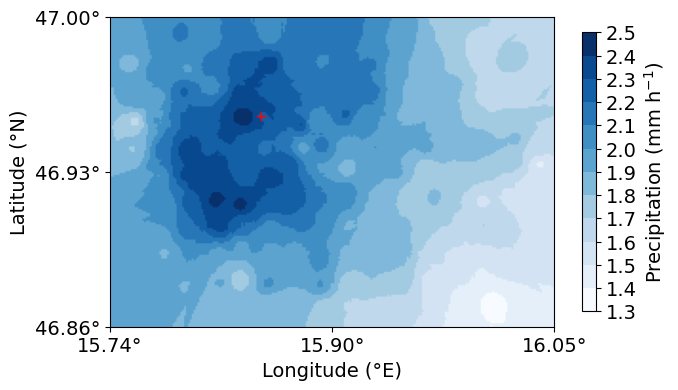

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f01.png')

In [15]:
overall_map = nan_average(np.stack([field.values for field in overall_grid_maps.values()]), PRECIP_STATISTIC)
extent = map_extent(next(iter(overall_grid_maps.values())))
levels = np.arange(np.floor(np.nanmin(overall_map) / 0.1) * 0.1, np.nanmax(overall_map) + 0.1, 0.1).round(6)
color_map = plt.get_cmap("Blues")

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(overall_map, origin="lower", extent=extent, cmap=color_map,
                  norm=BoundaryNorm(levels, color_map.N, clip=True), aspect="equal")
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
set_lonlat_ticks(ax, extent)
fig.colorbar(image, ax=ax, ticks=levels, label="Precipitation (mm h$^{-1}$)", shrink=0.5)
ax.plot(*RADIOMETER_XY, marker="+", color="red", markersize=7)
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)")
fig.tight_layout()
fig.savefig(PANEL_DIR / "precip_overall_map_mean.png", dpi=DPI, bbox_inches="tight")
plt.show()

save_composite("f01", [{"panels": [STATIC_DIR / "topography_map.png"]},
                       {"panels": [STATIC_DIR / "instruments_photo.png", PANEL_DIR / "precip_overall_map_mean.png"],
                        "fit_width": 0}])

### f02, f03 — flowcharts of the rain-type classification and of the convective probability

In [16]:
save_single("f02", STATIC_DIR / "flowchart_rain_type.pdf")
save_single("f03", STATIC_DIR / "flowchart_convective_probability.pdf")

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f03.png')

### f04 — precipitation of the classified events

(a) mean rain rate at the superstation over the normalised storm duration (5 % bins; dotted: events with a value per bin), (b) time-averaged gauge-grid maps; one colour scale per column (convective 0–5.2 mm h⁻¹, non-convective 0–2 mm h⁻¹).

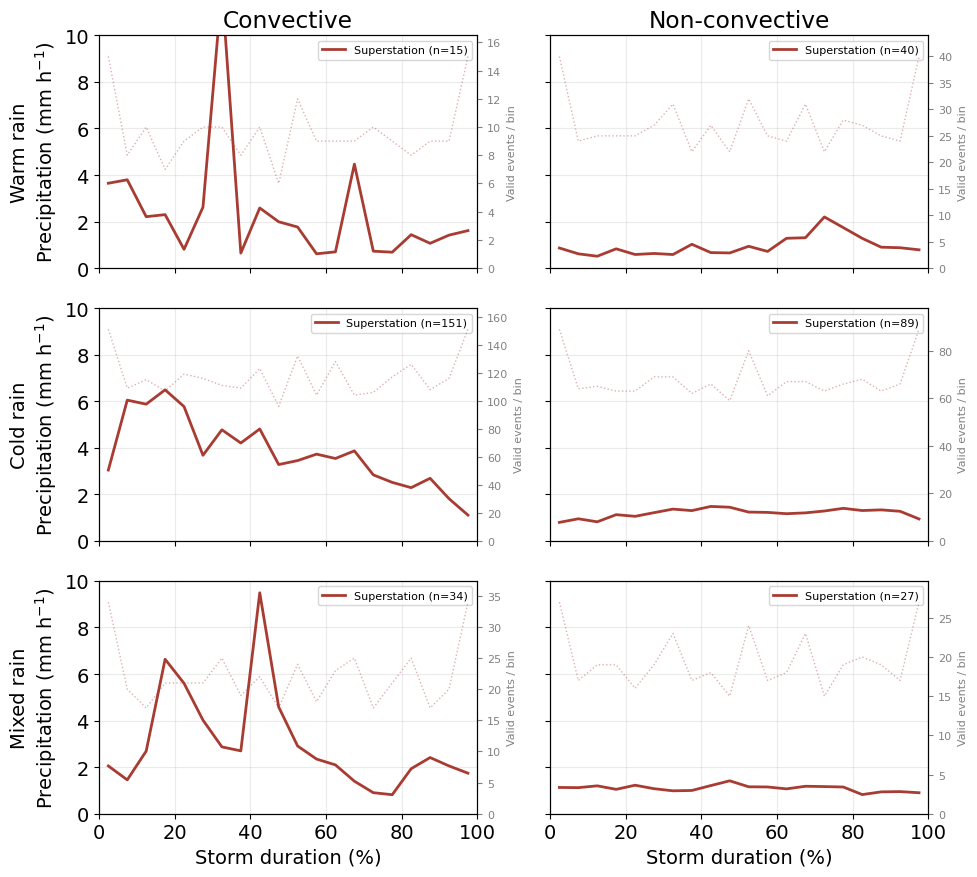

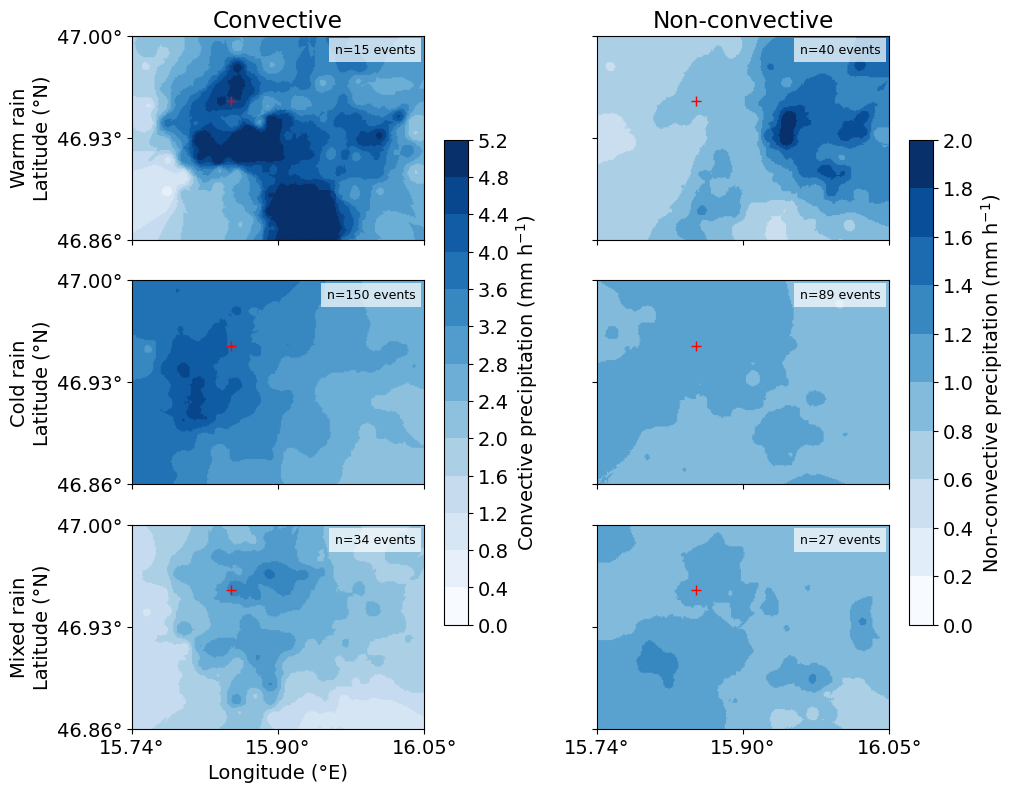

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f04.png')

In [17]:
# (a) station series
fig, axes = plt.subplots(3, 2, figsize=(10, 9), sharex=True, sharey=True)
style = {"color": "#a83c32", "linestyle": "-"}
for row, col, phase, rain_name, regime in PANELS:
    ax = axes[row, col]
    ax_count = ax.twinx()
    starts = pd.DatetimeIndex(select_precip_events(phase, regime).start.values)
    for station_id, show in STATION_VISIBLE.items():
        if not show:
            continue
        curves = [station_series[station_id][s] for s in starts if s in station_series[station_id]]
        if curves:
            summary, counts = composite(curves, STORM_PHASE_BINS, PRECIP_STATISTIC)
            n_valid = int(np.isfinite(np.array(curves)).any(axis=1).sum())
            ax.plot(STORM_PERCENT, summary, linewidth=2, label=f"{STATION_LABELS[station_id]} (n={n_valid})", **style)
            ax_count.plot(STORM_PERCENT, counts, ":", color=style["color"], linewidth=1, alpha=0.4)
    ax_count.set_ylim(0, max(1, len(starts)) * 1.1)
    if ax.lines:
        ax.legend(loc="upper right", fontsize=8, framealpha=0.8)
    ax.grid(alpha=0.25)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 10)
    ax_count.set_ylabel("Valid events / bin", fontsize=8, color="0.5")
    ax_count.tick_params(axis="y", colors="0.5", labelsize=8)
    if row == 0:
        ax.set_title(regime)
    if col == 0:
        ax.set_ylabel(f"{rain_name}\nPrecipitation (mm h$^{{-1}}$)")
    if row == 2:
        ax.set_xlabel("Storm duration (%)")
fig.tight_layout()
fig.savefig(PANEL_DIR / "precip_stations_mean_normalized.png", dpi=DPI, bbox_inches="tight")
plt.show()

# (b) gauge-grid maps
MAP_COLOR = {"Convective": {"vmin": 0, "vmax": 5.2, "n_levels": 14, "cmap": "Blues"},
             "Non-convective": {"vmin": 0, "vmax": 2, "n_levels": 11, "cmap": "Blues"}}
composites_map, n_maps = {}, {}
for row, col, phase, rain_name, regime in PANELS:
    starts = pd.DatetimeIndex(select_precip_events(phase, regime).start.values)
    fields = [gauge_grid_fields[s] for s in starts if s in gauge_grid_fields]
    n_maps[phase, regime] = len(fields)
    composites_map[phase, regime] = nan_average(np.stack([f.values for f in fields]), PRECIP_STATISTIC) if fields else None
scales = {regime: map_color_scale([composites_map[p, regime][np.isfinite(composites_map[p, regime])]
                                   for p, _ in RAIN_TYPE_ROWS if composites_map[p, regime] is not None],
                                  **MAP_COLOR[regime]) for regime in REGIME_COLUMNS}
extent = map_extent(next(iter(gauge_grid_fields.values())))

fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharex=True, sharey=True)
images = {}
for row, col, phase, rain_name, regime in PANELS:
    ax = axes[row, col]
    if composites_map[phase, regime] is not None:
        color_map, norm, _ = scales[regime]
        images[regime] = ax.imshow(composites_map[phase, regime], origin="lower", extent=extent,
                                   cmap=color_map, norm=norm, aspect="equal")
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.plot(*RADIOMETER_XY, marker="+", color="red", markersize=7)
    ax.text(0.97, 0.96, f"n={n_maps[phase, regime]} events", transform=ax.transAxes, ha="right", va="top",
            fontsize=9, bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.7})
    if row == 0:
        ax.set_title(regime)
    if col == 0:
        ax.set_ylabel(f"{rain_name}\nLatitude (°N)")
    if row == 2 and col == 0:
        ax.set_xlabel("Longitude (°E)")
set_lonlat_ticks(axes[-1, 0], extent)
for col, regime in enumerate(REGIME_COLUMNS):
    if regime in images:
        fig.colorbar(images[regime], ax=axes[:, col].tolist(), ticks=scales[regime][2],
                     label=f"{regime} precipitation (mm h$^{{-1}}$)", shrink=0.7)
fig.savefig(PANEL_DIR / "precip_gauge_grid_map_mean.png", dpi=DPI, bbox_inches="tight")
plt.show()

save_composite("f04", [{"panels": [PANEL_DIR / "precip_stations_mean_normalized.png",
                                   PANEL_DIR / "precip_gauge_grid_map_mean.png"]}])

### f05 — monthly LWP and IWV

Monthly median (solid) and P90 (dashed) of the six-hour pre-onset LWP and IWV in the warm and cold months and of the cloud-only time steps; right: distributions. Grey: no radiometer data.

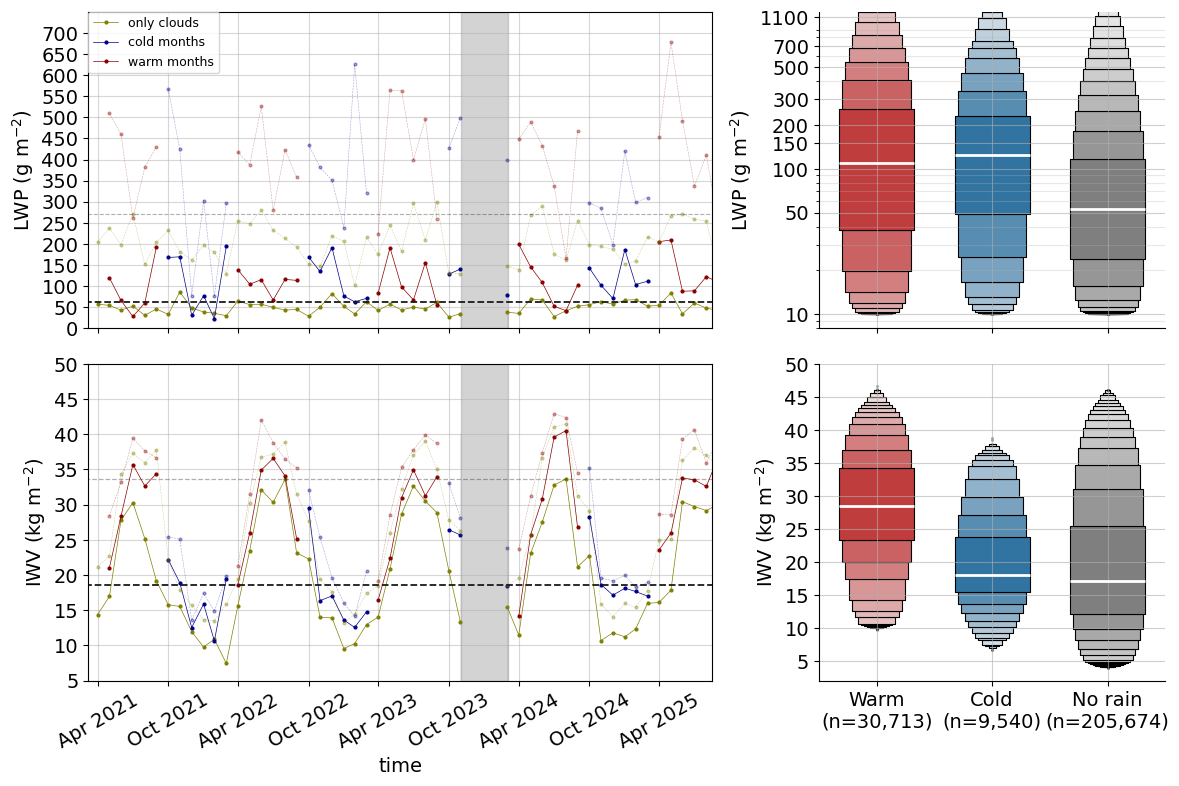

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f05.png')

In [18]:
# plot_lwp_boxen calls sns.set_theme(); rc_context restores the matplotlib style afterwards
with plt.rc_context():
    # the March 31 samples before the 2022-04-01 04:50 warm event are counted in April
    warm_monthly_time = pre_warm_lwp.time.values.copy()
    boundary_mask = ((warm_monthly_time >= np.datetime64("2022-04-01T04:50:00") - np.timedelta64(6, "h"))
                     & (warm_monthly_time < np.datetime64("2022-04-01T00:00:00")))
    warm_monthly_time[boundary_mask] += np.timedelta64(1, "D")
    pre_warm_monthly_plot = pre_warm_lwp.assign_coords(
        observation_time=("time", pre_warm_lwp.time.values), time=warm_monthly_time).sortby("time")

    fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex="col", gridspec_kw={"width_ratios": [1.8, 1]})
    series = [(only_cloud_times, "only clouds", "olive"), (pre_cold, "cold months", "darkblue"),
              (pre_warm_monthly_plot, "warm months", "darkred")]
    ticks = pd.date_range(start=measured_wegnL2_all_lwp.time[0].values,
                          end=measured_wegnL2_all_lwp.time[-1].values, freq="6ME")
    time_limits = (pd.to_datetime(str(measured_wegnL2_all_lwp.time[0].values)),
                   pd.to_datetime(str(measured_wegnL2_all_lwp.time[-1].values)))

    for ax, var, scale in [(axs[0, 0], "tclw", 1000), (axs[1, 0], "tcwv", 1)]:
        for data, label, color in series:
            values = (data[var] * scale)
            values = values.sortby("time") if label == "only clouds" else values.dropna("time").sortby("time")
            values.resample(time="1ME").reduce(np.nanmedian, dim="time").plot(
                label=label, marker="o", markersize=2, c=color, lw=0.5, ax=ax)
        for data, label, color in series:
            values = (data[var] * scale)
            values = values.sortby("time") if label == "only clouds" else values.dropna("time").sortby("time")
            values.resample(time="1ME").quantile(0.90, dim="time").plot(
                marker="o", markersize=2, c=color, lw=0.4, alpha=0.35, ls="--", ax=ax)
        ax.grid(alpha=0.5)
        ax.set_xticks(ticks)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        ax.xaxis.set_tick_params(rotation=30)
        ax.set_xlim(*time_limits)
        ax.vlines(["2023-12-01", "2024-04-01"], ymin=0, ymax=40, color="gray", linewidth=0.2)
        ax.axvspan("2023-12-01", "2024-04-01", alpha=0.5, color="darkgray")
        all_cloudy = measured_lwp_above_10g_v2[var] * scale
        ax.axhline(float(all_cloudy.reduce(np.nanmedian, dim="time").values), -600, 10, c="k", lw=1.3, ls="--")
        ax.axhline(float(all_cloudy.quantile(0.90, dim="time").values), -600, 10, c="k",
                   lw=0.8 if var == "tclw" else 0.9, ls="--", alpha=0.35)
        ax.set_title("")
    axs[0, 0].set_xlabel("")
    axs[0, 0].legend(loc="upper left", borderaxespad=0.0, fontsize=9)
    axs[0, 0].set_ylim(0, 750)
    axs[0, 0].set_yticks(list(range(0, 750, 50)))
    axs[0, 0].set_ylabel("LWP (g$~$m$^{-2}$)")
    axs[1, 0].set_ylim(5, 50)
    axs[1, 0].set_yticks(list(range(5, 55, 5)))
    axs[1, 0].set_ylabel("IWV (kg$~$m$^{-2}$)")

    _, ax3 = plot_lwp_boxen(pre_warm_lwp.tclw.values * 1000, pre_cold.tclw.values * 1000,
                            only_cloud_times.tclw.values * 1000, ax=axs[0, 1])
    ax3.set_ylim(8, 1200)
    ax3.set_yticks([10, 50, 100, 150, 200, 300, 500, 700, 1100], [10, 50, 100, 150, 200, 300, 500, 700, 1100])
    ax3.grid("x", alpha=0.6)
    _, ax4 = plot_iwv_boxen(pre_warm_lwp.tcwv.values, pre_cold.tcwv.values, only_cloud_times.tcwv.values,
                            ax=axs[1, 1])
    ax4.set_yticks(list(range(5, 55, 5)))
    ax4.set_ylim(2, 50)
    ax4.grid("x", alpha=0.6)

    plt.tight_layout()
    plt.savefig(PANEL_DIR / "Monthly_LWP_IWV_all.png", dpi=DPI, bbox_inches="tight")
    plt.show()

# sns.set_theme() also maps the colour codes "b", "g", "r" to the seaborn palette (not an rcParam)
import seaborn as sns
sns.set_color_codes("reset")

save_single("f05", PANEL_DIR / "Monthly_LWP_IWV_all.png")

### f06 — LWP and IWV anomalies before rain onset

Anomaly relative to the mean from −6 h to −3 h. (a) LWP and (b) IWV (radiometer, GNSS) in the warm season by regime and rain type, (c) cold season. Shading: 95 % confidence interval; hatched: last 15 min; grey bars: events per time step.

Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_warm_3x2_anomaly_10km.png
Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/IWV_HATPRO_GNSS_warm_3x2_anomaly_10km.png
Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/cold_combined_LWP_IWV_GNSS_anomaly.png


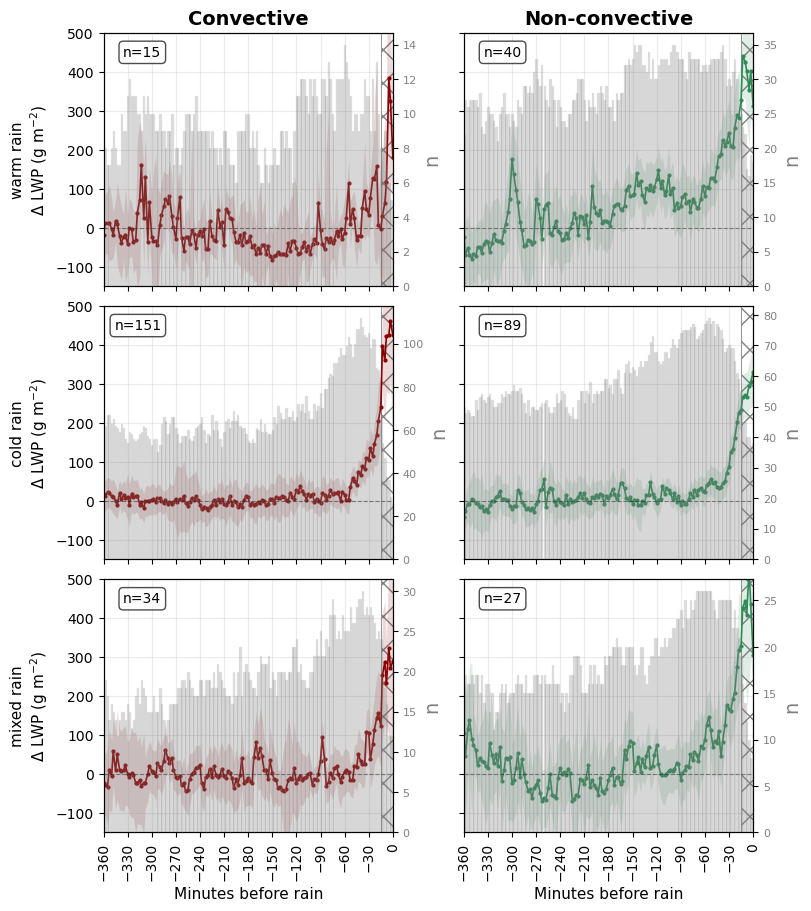

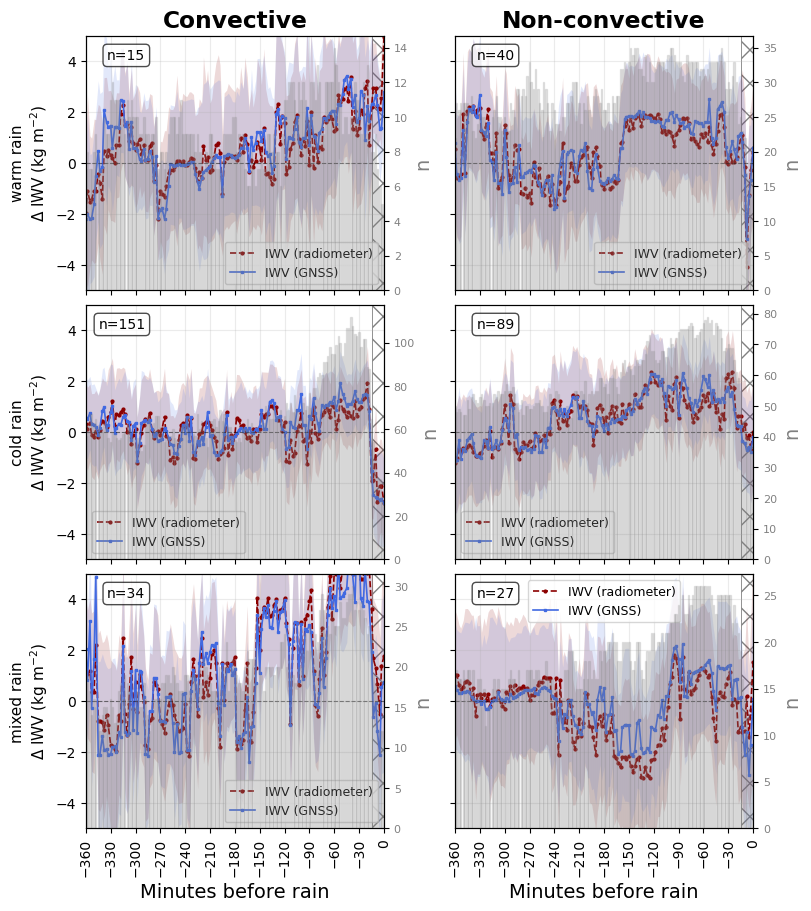

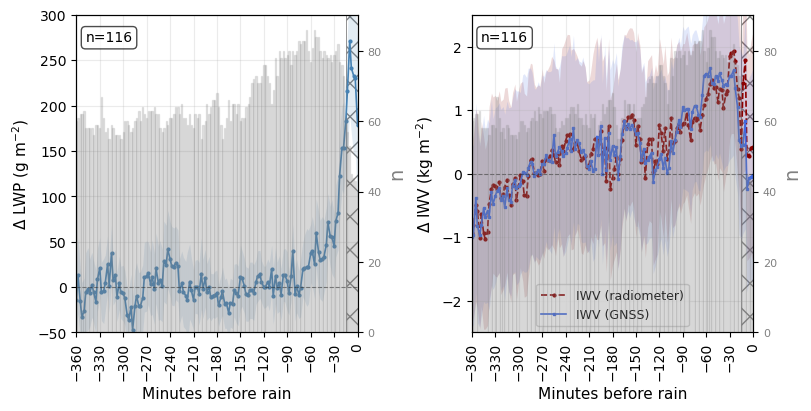

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f06.png')

In [19]:
plot_warm_regime_cloud_grid(
    warm_cloud_datasets=pre_warm_by_cloud, var="tclw", var_flag="tclw_dpg_flag",
    anomaly=True, anomaly_reference="long_tail", anomaly_tail_minutes=-180,
    phase_labels={"liquid": "warm rain", "ice": "cold rain", "mixed": "mixed rain"},
    xlim=(-360, 0), ylim=(-150, 500), figsize=(8, 9), show_ci=True, show_counts=True, sharey=True,
    suptitle=None, hatching_last_steps=15, savefig=f"{PANEL_DIR}/LWP_warm_3x2_anomaly_10km.png")

IWV_STYLE = dict(
    variables=("tcwv", "tcwv_gnss"), var_flags={"tcwv": "tcwv_dpg_flag", "tcwv_gnss": "tcwv_gnss_dpg_flag"},
    anomaly_reference="long_tail", show_counts=True, anomaly_tail_minutes=-180,
    phase_labels={"liquid": "warm rain", "ice": "cold rain", "mixed": "mixed rain"},
    variable_labels={"tcwv": "IWV (radiometer)", "tcwv_gnss": "IWV (GNSS)"},
    variable_colors={"tcwv": "darkred", "tcwv_gnss": "royalblue"},
    variable_linestyles={"tcwv": "--", "tcwv_gnss": "-"},
    xlim=(-360, 0), show_ci=True, sharey=True, hatching_last_steps=15)
plot_warm_regime_cloud_grid_multivar(
    warm_cloud_datasets=pre_warm_by_cloud, anomaly=True, ylim=(-5, 5),
    savefig=f"{PANEL_DIR}/IWV_HATPRO_GNSS_warm_3x2_anomaly_10km.png", **IWV_STYLE)

COLD_STYLE = dict(
    variables=("tclw", ("tcwv", "tcwv_gnss")),
    var_flags={"tclw": "tclw_dpg_flag", "tcwv": "tcwv_dpg_flag", "tcwv_gnss": "tcwv_gnss_dpg_flag"},
    anomaly_reference="long_tail", anomaly_tail_minutes=-180, show_ci=True, show_counts=True,
    xlim=(-360, 0), figsize=(8, 4),
    ylabels={"tclw": "LWP (g$~$m$^{-2}$)", ("tcwv", "tcwv_gnss"): "IWV (kg$~$m$^{-2}$)"},
    variable_labels={"tcwv": "IWV (radiometer)", "tcwv_gnss": "IWV (GNSS)"},
    variable_colors={"tclw": "steelblue", "tcwv": "darkred", "tcwv_gnss": "royalblue"},
    variable_linestyles={"tclw": "-", "tcwv": "--", "tcwv_gnss": "-"},
    hatching_last_steps=15, suptitle="")
plot_cold_events_panel(cold_dataset=pre_cold, anomaly=True, ylim={"tclw": (-50, 300), "tcwv": (-2.5, 2.5)},
                       savefig=f"{PANEL_DIR}/cold_combined_LWP_IWV_GNSS_anomaly.png", **COLD_STYLE)
plt.show()

save_composite("f06", [{"panels": [PANEL_DIR / "LWP_warm_3x2_anomaly_10km.png",
                                   PANEL_DIR / "IWV_HATPRO_GNSS_warm_3x2_anomaly_10km.png"]},
                       {"panels": [PANEL_DIR / "cold_combined_LWP_IWV_GNSS_anomaly.png"]}])

### f07 — cloud base height before rain onset: (a) warm season, (b) cold season

Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/cbh_warm_3x2_absolute_10km.png
Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/cbh_cold_combined_absolute_10km.png


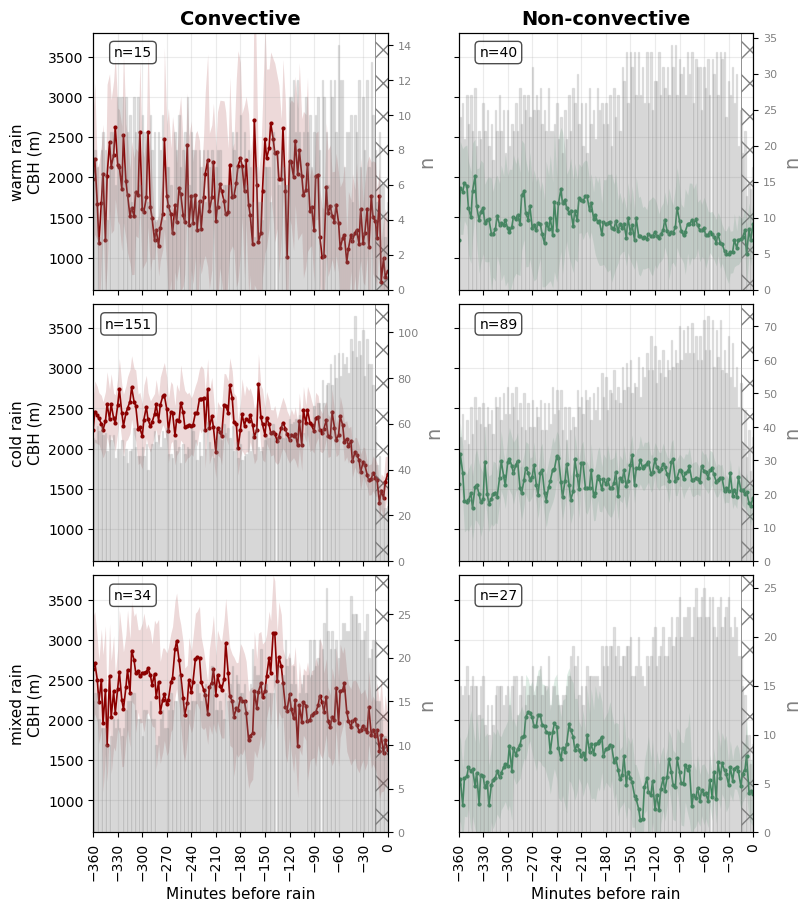

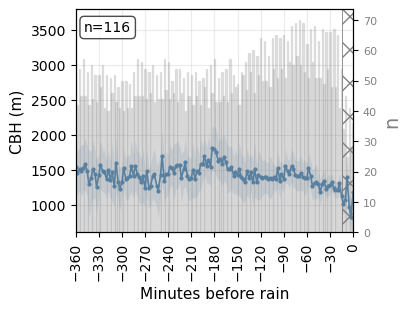

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f07.png')

In [20]:
plot_warm_regime_cloud_grid(
    warm_cloud_datasets=pre_warm_by_cloud, var="cbh", var_flag="cbh_dpg_flag", anomaly=False,
    phase_labels={"liquid": "warm rain", "ice": "cold rain", "mixed": "mixed rain"},
    xlim=(-360, 0), ylim=(600, 3800), figsize=(8, 9), ylabel="CBH (m)", show_ci=True, sharey=True,
    show_counts=True, suptitle=None, hatching_last_steps=15,
    savefig=f"{PANEL_DIR}/cbh_warm_3x2_absolute_10km.png")
plot_cold_events_panel(
    cold_dataset=pre_cold, variables=("cbh",), var_flags={"cbh": "cbh_dpg_flag"}, xlim=(-360, 0),
    ylim=(600, 3800), figsize=(4, 3), anomaly=False, anomaly_reference="long_tail", anomaly_tail_minutes=-180,
    ylabels={"cbh": "CBH (m)"}, show_ci=True, show_counts=True, suptitle=None, hatching_last_steps=15,
    savefig=f"{PANEL_DIR}/cbh_cold_combined_absolute_10km.png")
plt.show()

save_composite("f07", [{"panels": [PANEL_DIR / "cbh_warm_3x2_absolute_10km.png"]},
                       {"panels": [PANEL_DIR / "cbh_cold_combined_absolute_10km.png"]}])

### f08 — cloud fraction before rain onset

Fraction of measured time steps with LWP > 10 g m⁻² (green) and infrared cloud fraction, narrow band 9.6–11.5 µm (dashed); mean over events in 10-min bins. Dotted (right axis): events with a value per bin.

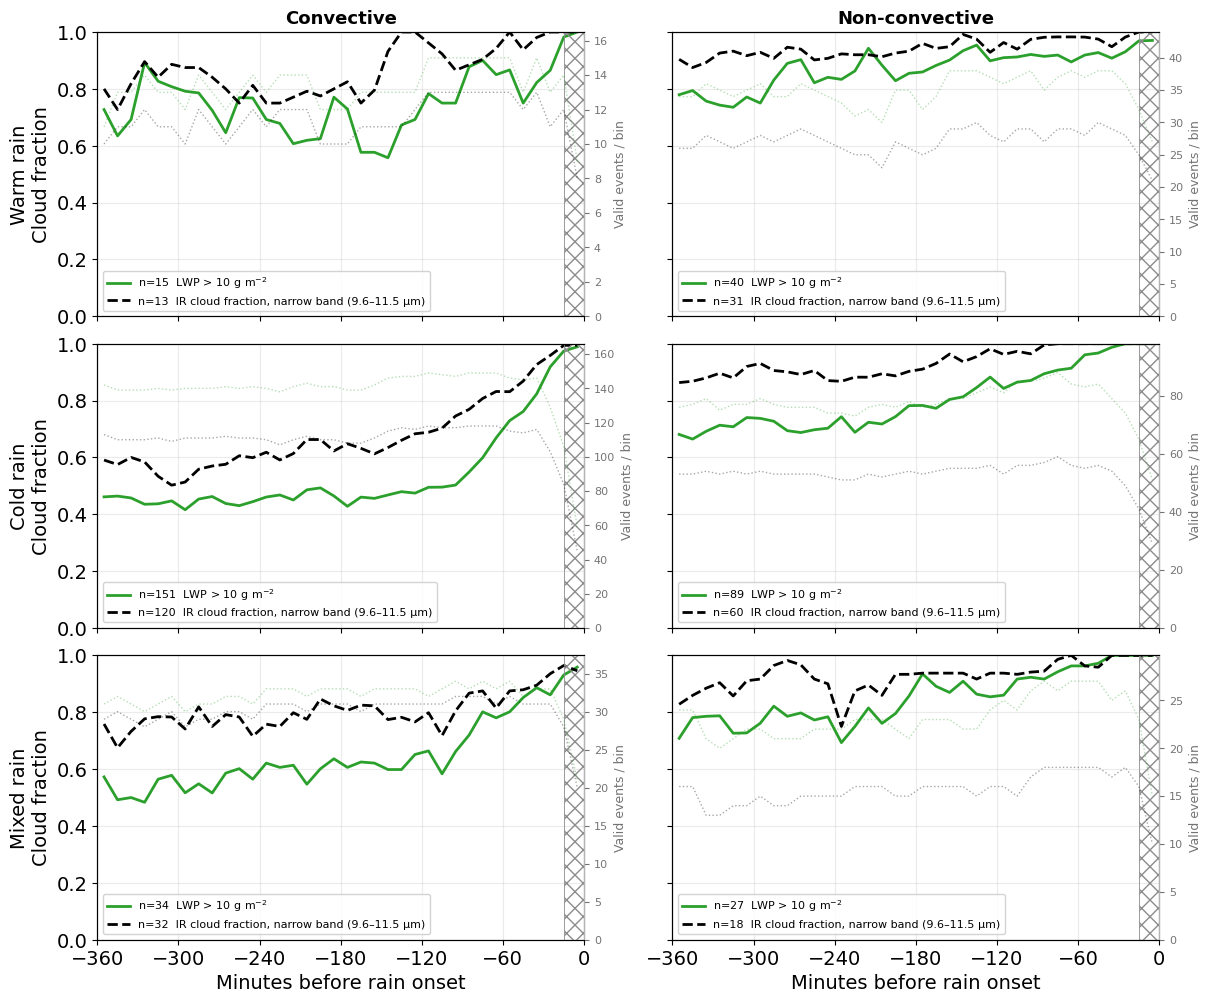

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f08.png')

In [21]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True, sharey=True, constrained_layout=True)
cf_styles = [("cf_lwp", "LWP > 10 g m$^{-2}$", "#2ca02c", "-"),
             ("cf_csx", "IR cloud fraction, narrow band (9.6–11.5 µm)", "k", "--")]
for row, col, phase, rain_name, regime in PANELS:
    key = f"{regime} · {phase}"
    ax = axes[row, col]
    for metric, label, color, linestyle in cf_styles:
        ax.plot(BIN_CENTERS_MIN, cf_composites[key][metric], color=color, linestyle=linestyle, lw=2.0,
                label=f"n={cf_coverage.loc[key, f'{metric}_events']}  {label}")
    add_event_count_axis(ax, BIN_CENTERS_MIN, [(cf_counts[key][m], c) for m, _, c, _ in cf_styles],
                         len(regime_starts[key]))
    format_pre_onset_panel(ax, row, col, rain_name, regime, "Cloud fraction")
    ax.set_ylim(0, 1)
    ax.legend(loc="lower left", fontsize=8, framealpha=0.85)
fig.suptitle("", fontsize=14)
fig.savefig(PANEL_DIR / "REV1_pre_onset_L2a_cloud_fraction_10min_bin.png", dpi=DPI, bbox_inches="tight")
plt.show()

save_single("f08", PANEL_DIR / "REV1_pre_onset_L2a_cloud_fraction_10min_bin.png")

### f09 — joint evolution of ΔLWP and ΔIWV

Top: ΔLWP vs ΔIWV 30 min before onset (r: Pearson correlation of all events). Bottom: mean trajectory from −3 h to onset; ellipses: 95 % confidence region of the mean.

warm rain: 39/55 events had valid LWP & IWV at -30±2 min
cold rain: 167/240 events had valid LWP & IWV at -30±2 min
mixed rain: 53/61 events had valid LWP & IWV at -30±2 min

Balanced event counts (valid at all 7 nodes):
       convective / warm rain: 8/15
       convective / cold rain: 50/151
       convective / mixed rain: 17/34
   non-convective / warm rain: 29/40
   non-convective / cold rain: 51/89
   non-convective / mixed rain: 20/27
Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/lwp_iwv_scatter_trajectory_10km.png


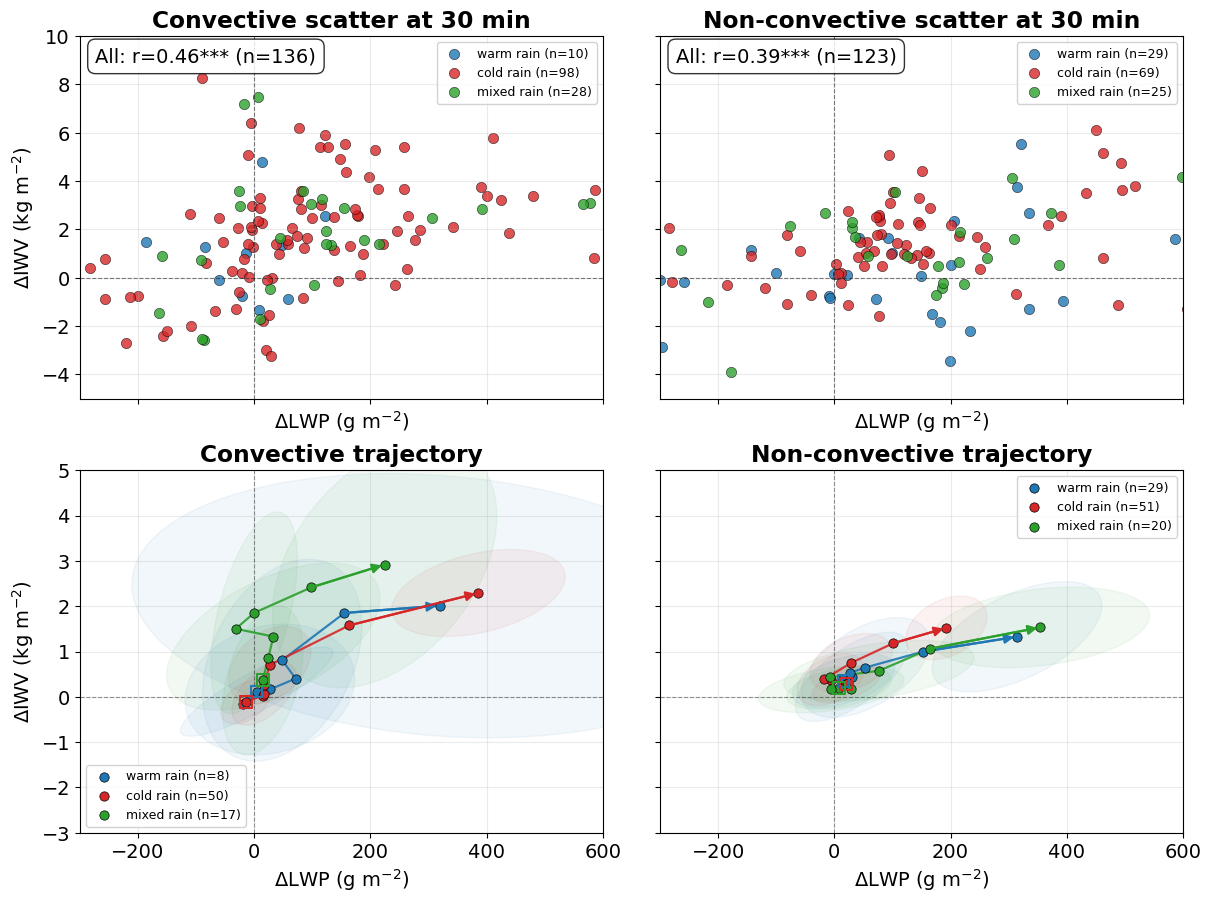

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f09.png')

In [22]:
fig, axes = plot_combined_lwp_iwv_summary(pre_warm_by_cloud, PANEL_DIR)
for ax in np.ravel(axes):                     # the helper writes "Delta LWP"; the paper uses "ΔLWP"
    ax.set_xlabel(ax.get_xlabel().replace("Delta ", "Δ"))
    ax.set_ylabel(ax.get_ylabel().replace("Delta ", "Δ"))
fig.savefig(PANEL_DIR / "lwp_iwv_scatter_trajectory_10km.png", dpi=DPI, bbox_inches="tight")
plt.show()

save_single("f09", PANEL_DIR / "lwp_iwv_scatter_trajectory_10km.png")

### f10–f13 — two example events

Height–time sections above the radiometer. Black line: −5 °C isotherm from the radiometer (grey: vertical grid cell); purple hatching: rain detected by the gauge. f10/f12: (a) X-band L2 rain intensity with cloud base, (b) attenuation-corrected Z_h with LWP. f11/f13: Z_DR with IWV.

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_Zh_20230608_L1.png


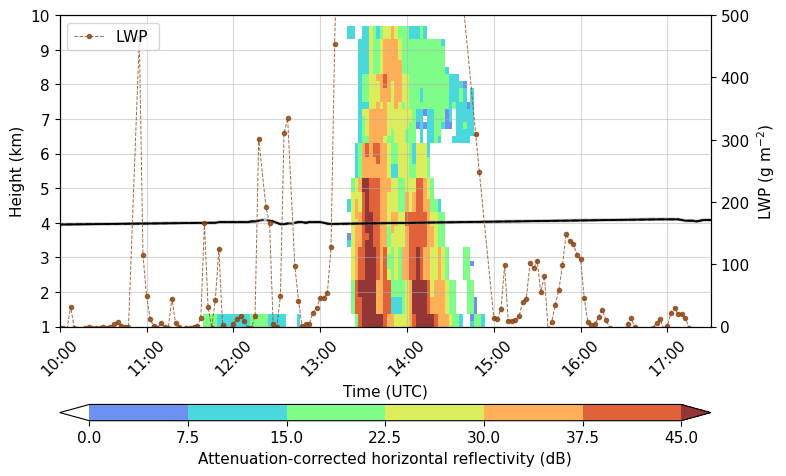

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/IWV_zdr_20230608.png


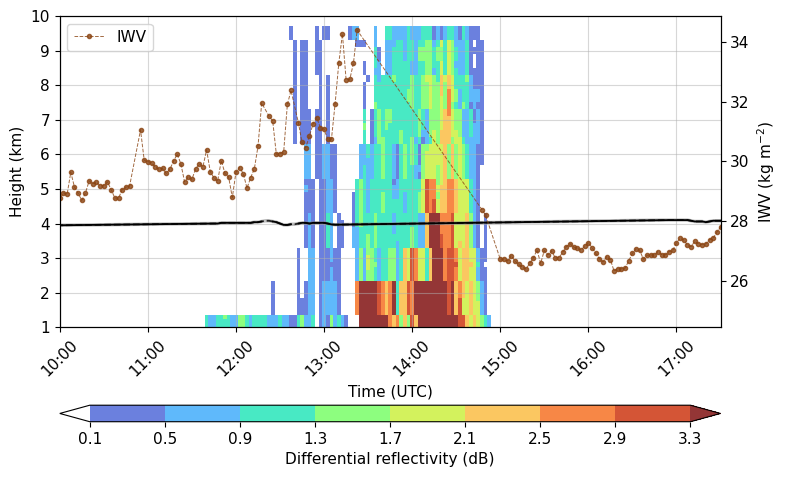

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_precip_20230608.png


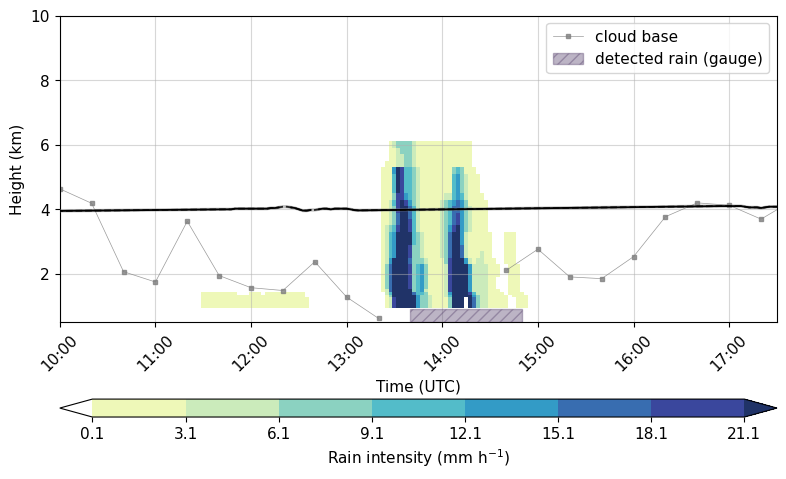

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f11.png')

In [23]:
with plt.rc_context({"font.size": 11}):
    plot_event("2023-06-08")
save_composite("f10", [{"panels": [PANEL_DIR / "LWP_precip_20230608.png", PANEL_DIR / "LWP_Zh_20230608_L1.png"]}])
save_single("f11", PANEL_DIR / "IWV_zdr_20230608.png")

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_Zh_20240612_L1.png


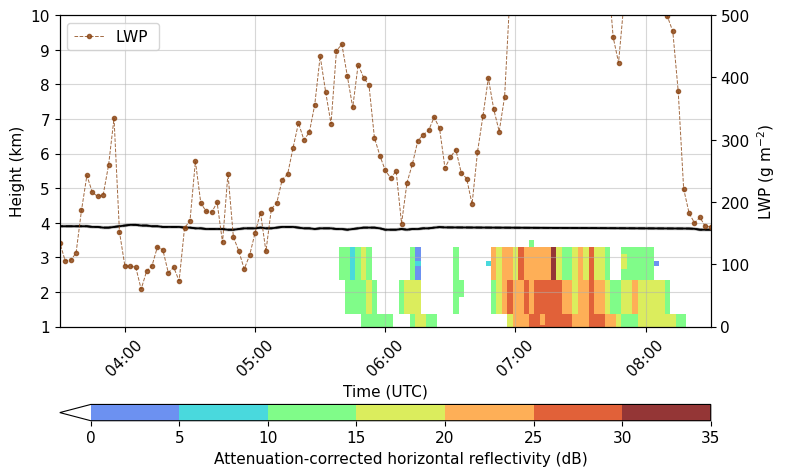

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/IWV_zdr_20240612.png


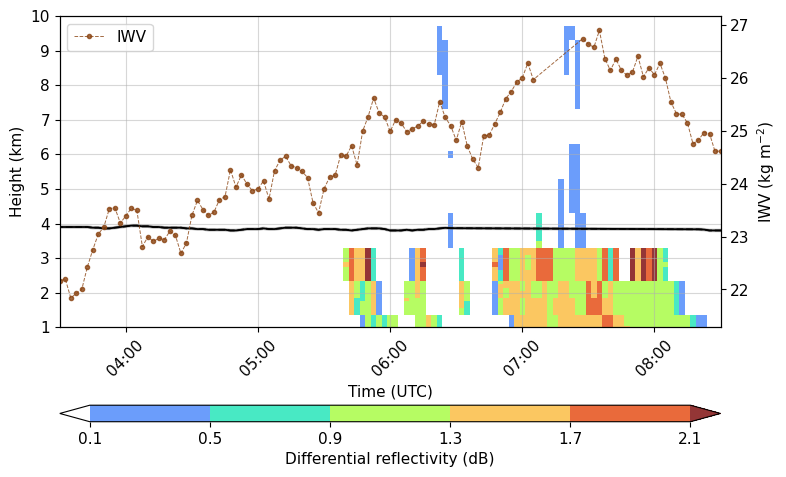

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_precip_20240612.png


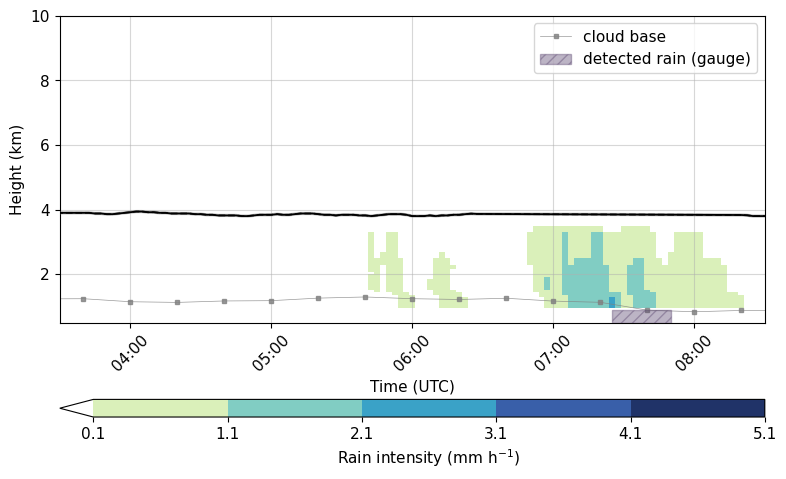

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/f13.png')

In [24]:
with plt.rc_context({"font.size": 11}):
    plot_event("2024-06-12")
save_composite("f12", [{"panels": [PANEL_DIR / "LWP_precip_20240612.png", PANEL_DIR / "LWP_Zh_20240612_L1.png"]}])
save_single("f13", PANEL_DIR / "IWV_zdr_20240612.png")

## 8. Appendix figures (fA01 is made in notebook 02)

### fA02 — ERA5 and radiometer: (a) monthly median LWP (LWP > 10 g m⁻²), (b) monthly median IWV (with GNSS)

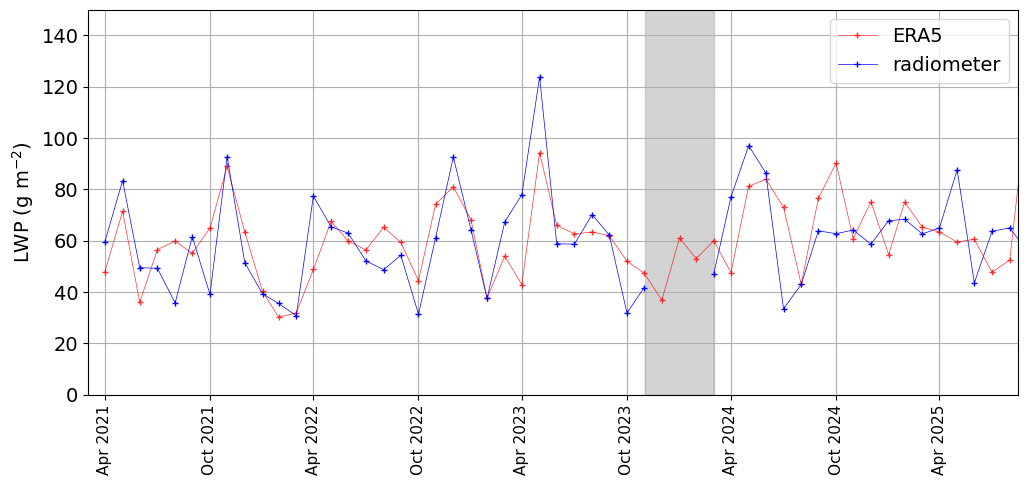

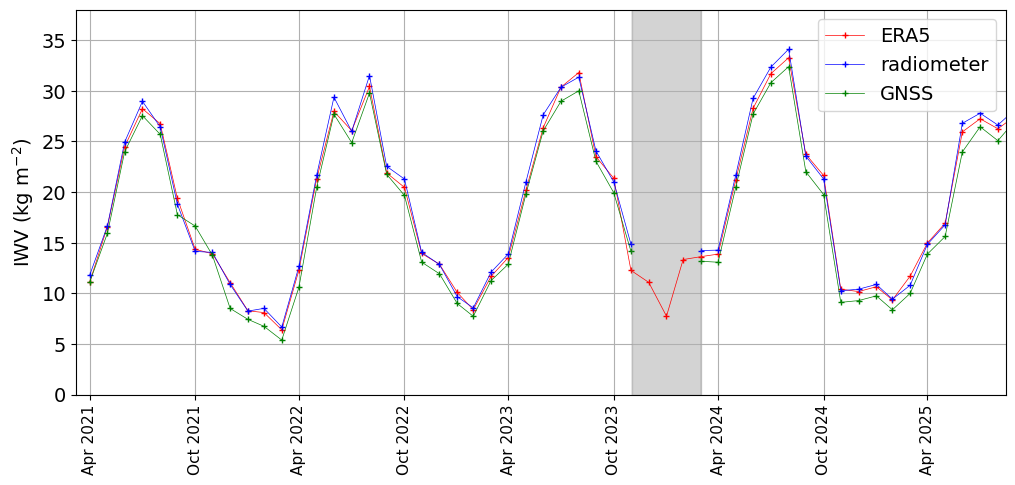

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/fA02.png')

In [25]:
monthly_era5 = era5_radiometer_location_lwp_min.resample(time="1ME").median()
ticks = pd.date_range(start=measured_wegnL2_all_lwp.time[0].values,
                      end=measured_wegnL2_all_lwp.time[-1].values, freq="6ME")

fig, ax = plt.subplots(figsize=(12, 5))
(monthly_era5.tclw * 1000).plot(label="ERA5", marker="+", markersize=4, c="r", lw=0.5, alpha=0.8)
(measured_lwp_above_10g_v2.tclw.resample(time="1ME").reduce(np.nanmedian, dim="time") * 1000).plot(
    label="radiometer", marker="+", markersize=4, c="b", lw=0.5)
ax.vlines(["2023-12-01", "2024-04-01"], ymin=0, ymax=40, color="gray", linewidth=0.2)
ax.axvspan("2023-12-01", "2024-04-01", alpha=0.5, color="darkgray")
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=90, fontsize=11)
plt.grid()
plt.legend()
plt.ylim(0, 150)
plt.title("")
plt.xlabel("")
plt.ylabel("LWP (g$~$m$^{-2}$)")
plt.xlim(pd.to_datetime("2021-04-01"), pd.to_datetime("2025-09-15"))
plt.savefig(PANEL_DIR / "ERA5_monthly_comparison_TCLW_TCRW.png", dpi=DPI, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
era5_ts_cr.resample(time="1ME").median().tcwv.plot(label="ERA5", marker="+", markersize=4, c="r", lw=0.5)
measured_wegnL2_all_iwv.tcwv.resample(time="1ME").reduce(np.nanmedian, dim="time").plot(
    label="radiometer", marker="+", markersize=4, c="b", lw=0.5)
(wegn_iwv_v2_gnss.where((wegnL2_all_iwv_st171.tcwv_dpg_flag == 0).compute(), drop=True)
 .tcwv.resample(time="1ME").reduce(np.nanmedian, dim="time")).plot(
    label="GNSS", marker="+", markersize=4, c="g", lw=0.5)
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=90, fontsize=11)
plt.xlim(pd.to_datetime(str(measured_wegnL2_all_lwp.time[0].values)),
         pd.to_datetime(str(measured_wegnL2_all_lwp.time[-1].values)))
ax.set_xlabel("")
ax.set_ylabel("IWV (kg$~$m$^{-2}$)")
ax.vlines(["2023-12-01", "2024-04-01"], ymin=0, ymax=40, color="gray", linewidth=0.2)
ax.axvspan("2023-12-01", "2024-04-01", alpha=0.5, color="darkgray")
plt.title("")
plt.grid()
plt.legend()
plt.ylim(0, 38)
plt.savefig(PANEL_DIR / "ERA5_monthly_comparison_IWV.png", dpi=DPI, bbox_inches="tight")
plt.show()

save_composite("fA02", [{"panels": [PANEL_DIR / "ERA5_monthly_comparison_TCLW_TCRW.png"]},
                        {"panels": [PANEL_DIR / "ERA5_monthly_comparison_IWV.png"]}])

### fA03 — absolute LWP and IWV before rain onset: (a) LWP, (b) IWV in the warm season, (c) cold season

Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_warm_10km_limit_absolute.png
Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/IWV_HATPRO_GNSS_warm_10km_limit_absolute_10km.png
Saved to /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/cold_combined_LWP_IWV_GNSS_absolute.png


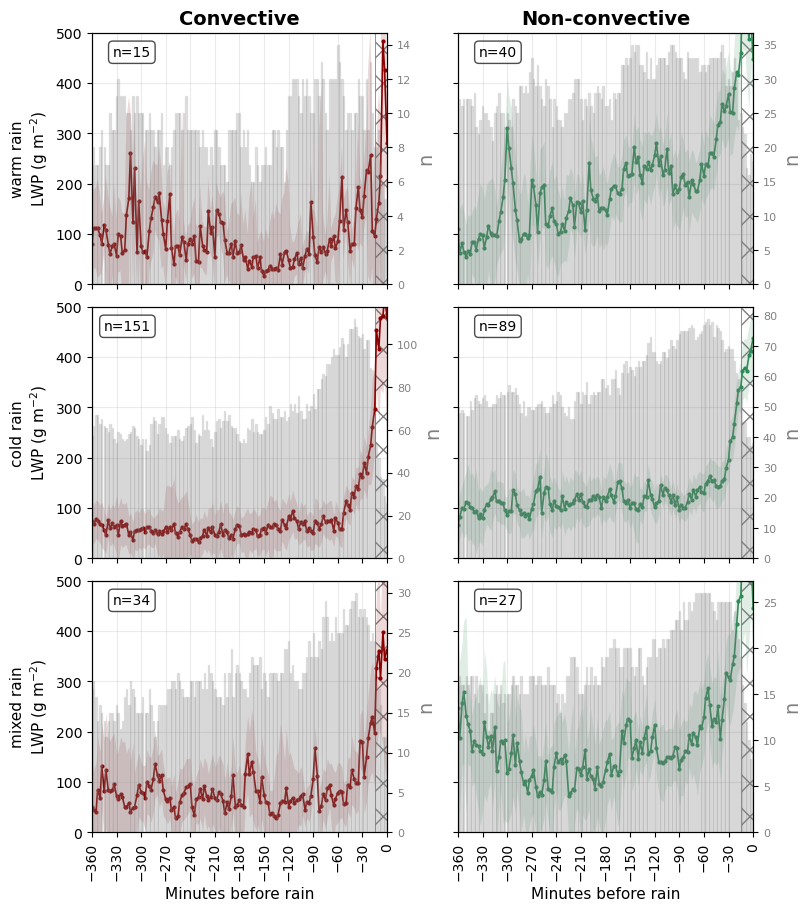

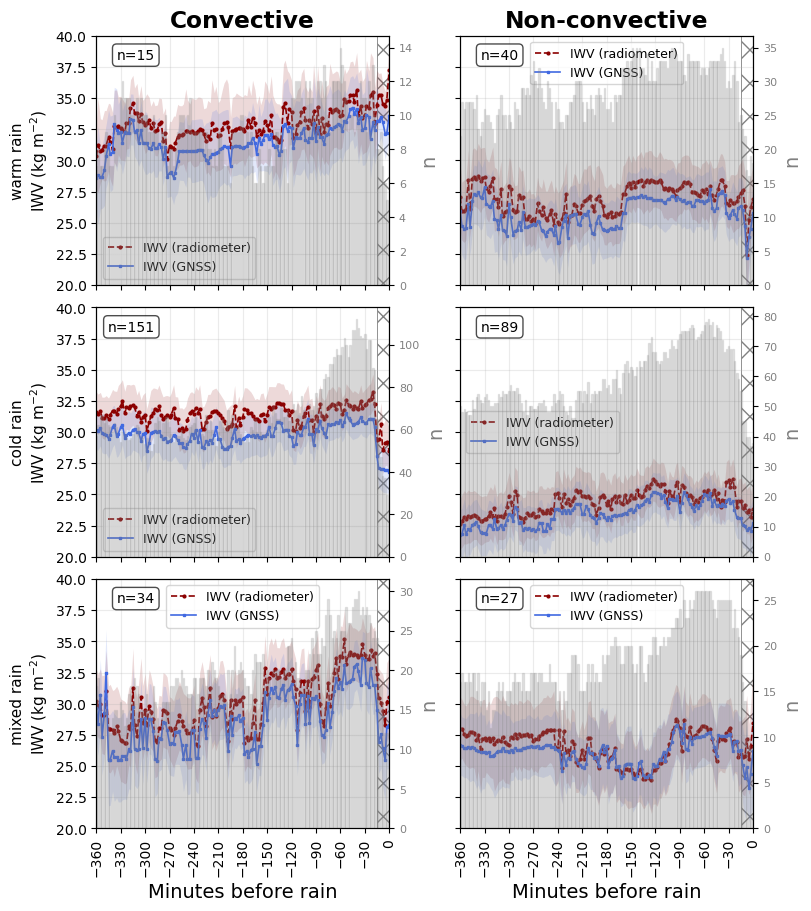

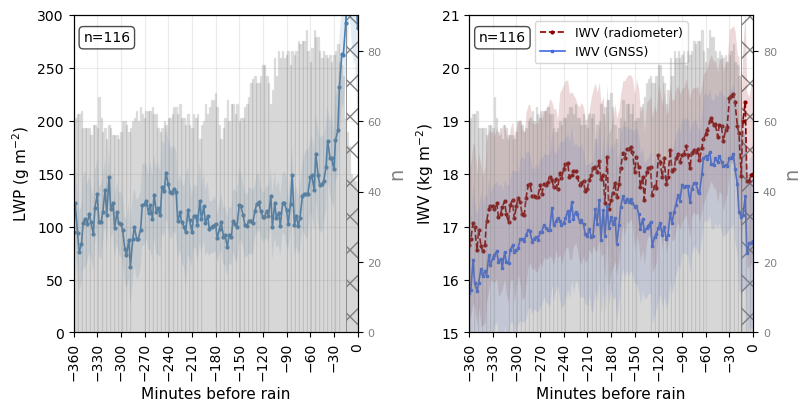

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/fA03.png')

In [26]:
plot_warm_regime_cloud_grid(
    warm_cloud_datasets=pre_warm_by_cloud, var="tclw", var_flag="tclw_dpg_flag", anomaly=False,
    anomaly_reference="long_tail", anomaly_tail_minutes=-180,
    phase_labels={"liquid": "warm rain", "ice": "cold rain", "mixed": "mixed rain"},
    xlim=(-360, 0), ylim=(0, 500), figsize=(8, 9), show_ci=True, show_counts=True, suptitle=None,
    hatching_last_steps=15, sharey=True, savefig=f"{PANEL_DIR}/LWP_warm_10km_limit_absolute.png")
plot_warm_regime_cloud_grid_multivar(
    warm_cloud_datasets=pre_warm_by_cloud, anomaly=False, ylim=(20, 40),
    savefig=f"{PANEL_DIR}/IWV_HATPRO_GNSS_warm_10km_limit_absolute_10km.png", **IWV_STYLE)
plot_cold_events_panel(cold_dataset=pre_cold, anomaly=False, ylim={"tclw": (0, 300), "tcwv": (15, 21)},
                       savefig=f"{PANEL_DIR}/cold_combined_LWP_IWV_GNSS_absolute.png", **COLD_STYLE)
plt.show()

save_composite("fA03", [{"panels": [PANEL_DIR / "LWP_warm_10km_limit_absolute.png",
                                    PANEL_DIR / "IWV_HATPRO_GNSS_warm_10km_limit_absolute_10km.png"]},
                        {"panels": [PANEL_DIR / "cold_combined_LWP_IWV_GNSS_absolute.png"]}])

### fA04 — hour of day of the cloudy pre-onset time steps (time stamps in UTC)

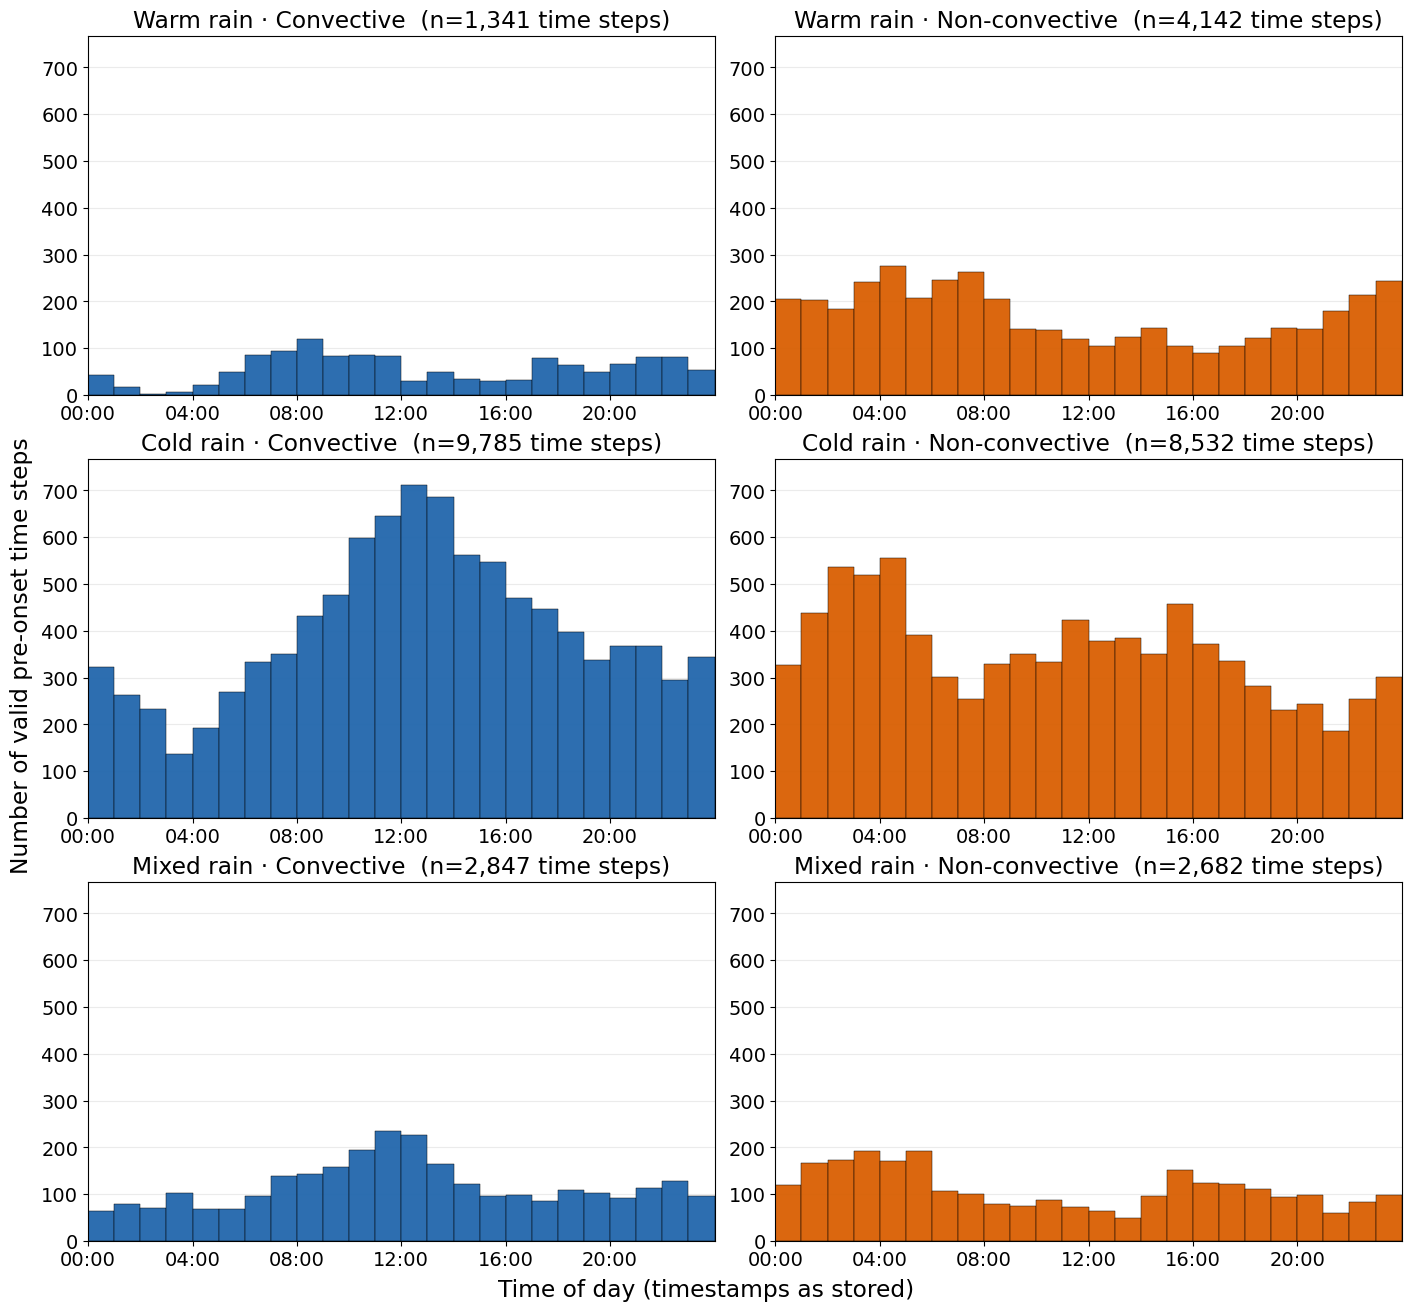

PosixPath('/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/fA04.png')

In [32]:
fig = plt.figure(figsize=(14, 13), constrained_layout=True)
gs = fig.add_gridspec(3, 2)
ymax = max(1, int(diurnal_lwp_counts.to_numpy().max())) * 1.08
for row, col, phase, rain_name, regime in PANELS:
    ax = fig.add_subplot(gs[row, col])
    counts = diurnal_lwp_counts[f"{regime} · {phase}"].to_numpy()
    ax.bar(DIURNAL_HOURS, counts, width=1, align="edge", color="#2166ac" if regime == "Convective" else "#d95f02",
           edgecolor="black", linewidth=0.35, alpha=0.95)
    ax.set(title=f"{rain_name} · {regime}  (n={counts.sum():,} time steps)", xlim=(0, 24), ylim=(0, ymax))
    ax.set_xticks(np.arange(0, 24, 4), [f"{hour:02d}:00" for hour in range(0, 24, 4)])
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
fig.supxlabel("Time of day (timestamps as stored)")
fig.supylabel("Number of valid pre-onset time steps")
fig.savefig(PANEL_DIR / "REV1_pre_onset_LWP_diurnal_hourly.png", dpi=DPI, bbox_inches="tight")
plt.show()

save_single("fA04", PANEL_DIR / "REV1_pre_onset_LWP_diurnal_hourly.png")

### fA05–fA10 — three more events (same layout as f10–f13)

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_Zh_20240819_L1.png


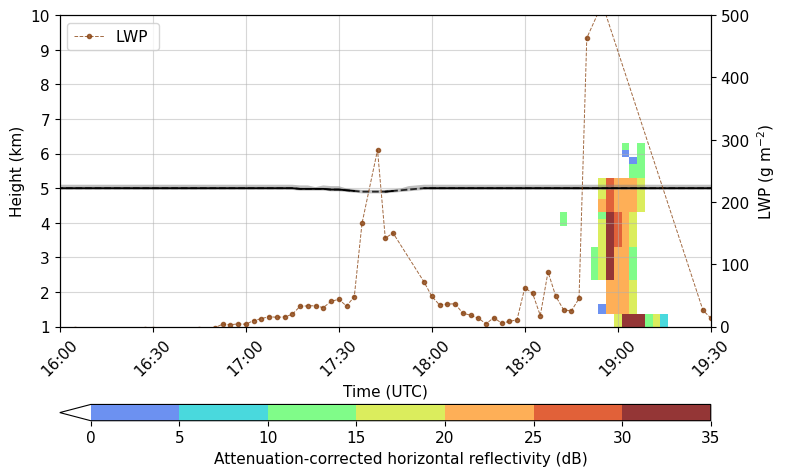

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/IWV_zdr_20240819.png


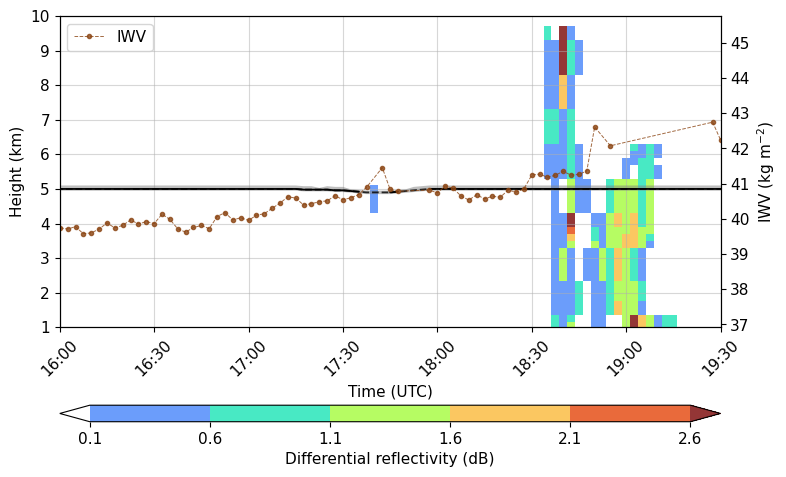

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_precip_20240819.png


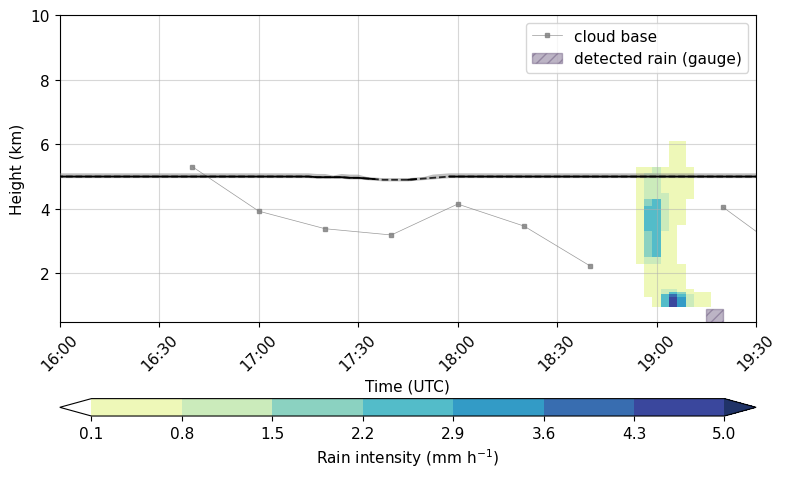

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_Zh_20240516_L1.png


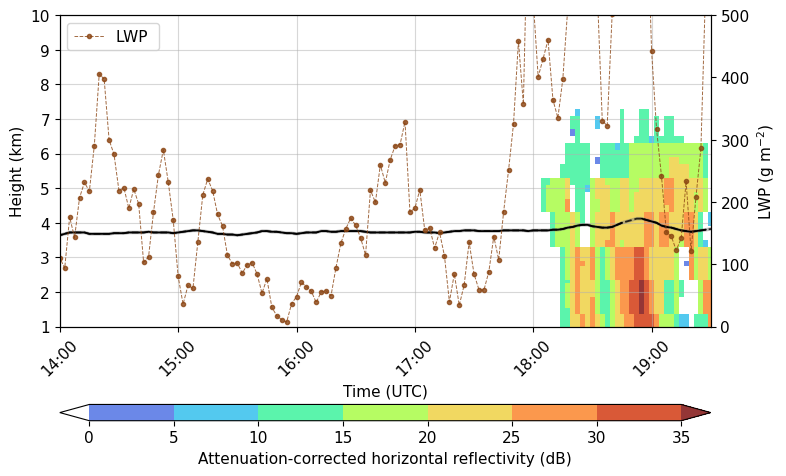

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/IWV_zdr_20240516.png


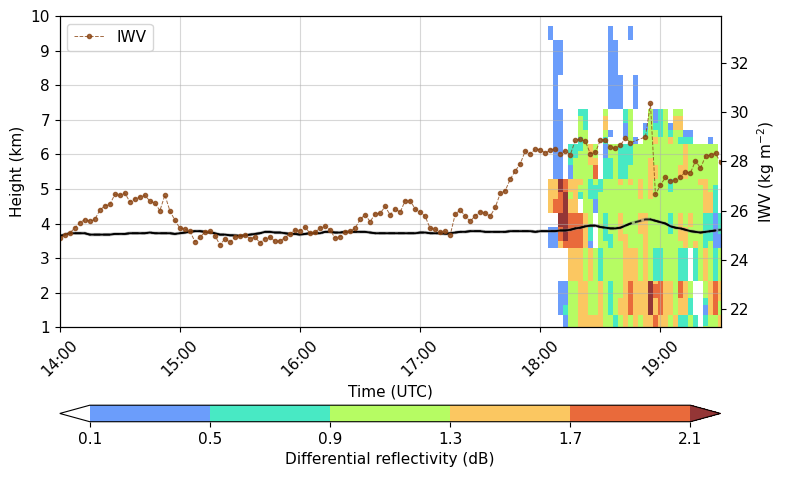

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_precip_20240516.png


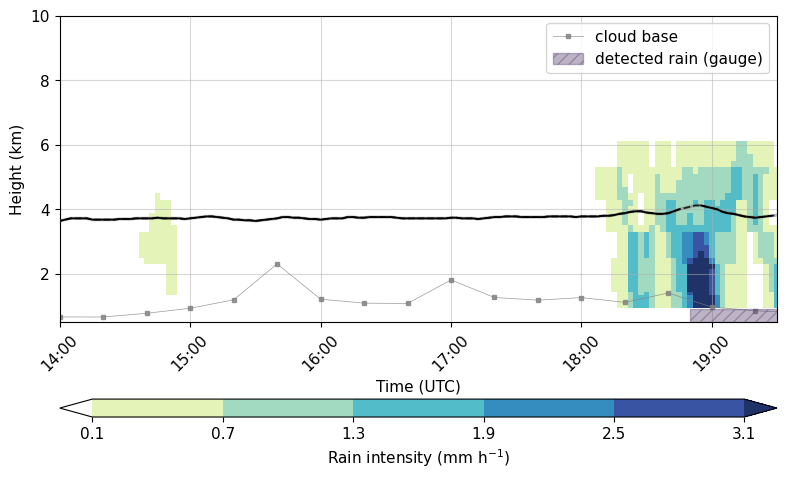

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_Zh_20250316_L1.png


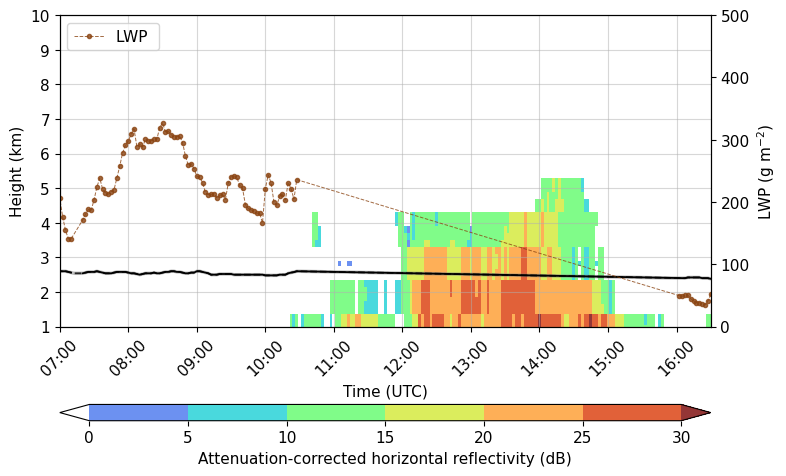

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/IWV_zdr_20250316.png


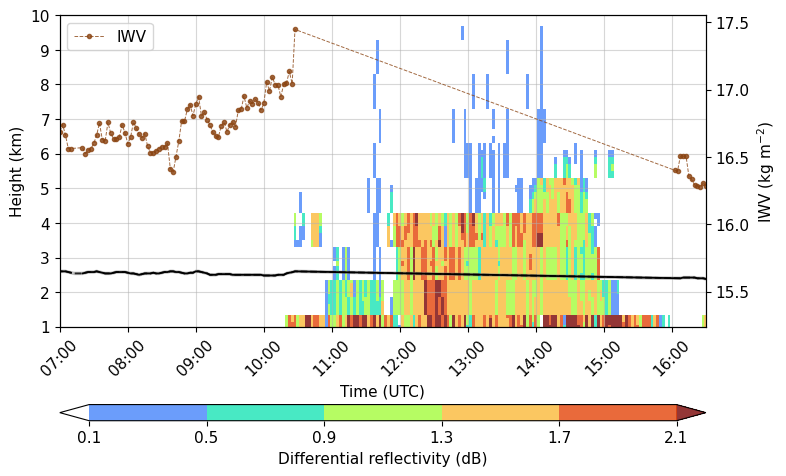

Saved: /home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/figures/panels/LWP_precip_20250316.png


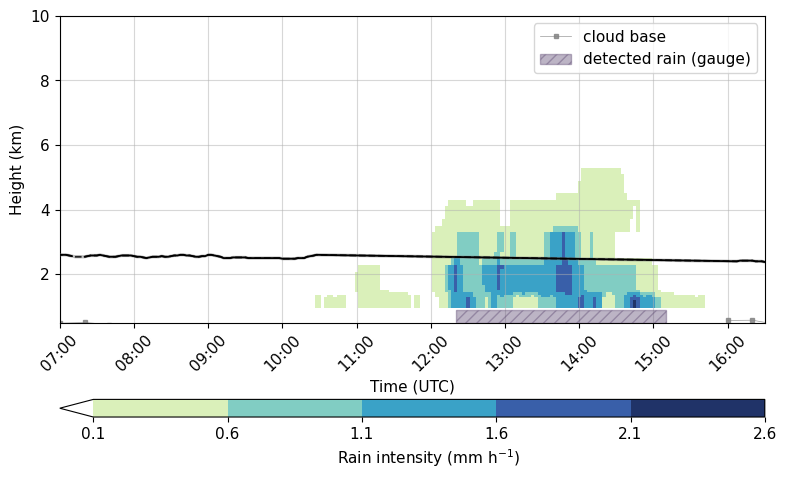

In [33]:
for event_date, (fig_precip_zh, fig_zdr) in {"2024-08-19": ("fA05", "fA06"),
                                             "2024-05-16": ("fA07", "fA08"),
                                             "2025-03-16": ("fA09", "fA10")}.items():
    with plt.rc_context({"font.size": 11}):
        plot_event(event_date)
    compact = event_date.replace("-", "")
    save_composite(fig_precip_zh, [{"panels": [PANEL_DIR / f"LWP_precip_{compact}.png",
                                               PANEL_DIR / f"LWP_Zh_{compact}_L1.png"]}])
    save_single(fig_zdr, PANEL_DIR / f"IWV_zdr_{compact}.png")

## 9. Journal limits: 300 dpi, width ≥ 8 cm, < 5 MB per file, < 30 MB in total

In [34]:
rows = []
for path in sorted(FIG_DIR.glob("f*.png")):
    with Image.open(path) as image:
        width_px, height_px = image.size
        dpi = round(image.info["dpi"][0])
    rows.append({"file": path.name, "width_px": width_px, "height_px": height_px, "dpi": dpi,
                 "width_cm": round(width_px / dpi * 2.54, 1), "height_cm": round(height_px / dpi * 2.54, 1),
                 "size_MB": round(path.stat().st_size / 1e6, 2)})
check = pd.DataFrame(rows).set_index("file")
check["ok"] = (check["dpi"] == 300) & (check["width_cm"] >= 8) & (check["size_MB"] < 5)
display(check)
print(f"Total size: {check['size_MB'].sum():.1f} MB (limit 30 MB); all files ok: {bool(check['ok'].all())}")

,width_px,height_px,dpi,width_cm,height_cm,size_MB,ok
file,,,,,,,
f01.png,3614,3325,300,30.6,28.2,4.97,True
f02.png,1514,1516,300,12.8,12.8,0.12,True
f03.png,2002,3382,300,17.0,28.6,0.52,True
f04.png,6001,2712,300,50.8,23.0,0.82,True
f05.png,3530,2358,300,29.9,20.0,0.72,True
f06.png,4908,4168,300,41.6,35.3,2.23,True
f07.png,2434,3868,300,20.6,32.7,0.91,True
f08.png,3634,3009,300,30.8,25.5,0.81,True
f09.png,3634,2709,300,30.8,22.9,0.72,True


Total size: 17.5 MB (limit 30 MB); all files ok: True
